# Le gain d'un entraînement multi-vecteur conscient du token pooling (index ÷4) se retrouve-t-il en français ?

> **En bref.** Le gain annoncé n'est pas retrouvé en français : l'écart est négligeable et non significatif, et la compression coûte déjà peu à un modèle ordinaire. Résultat non concluant, limité par un seul entraînement et une perte réimplémentée. nDCG@10 à pool_factor=4 : 77,2 [75,3 ; 79,1] pour Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss, contre 77 [75 ; 78,8] pour Multi-vecteur entraîné normalement (1204 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | En français, à pool_factor=4, le modèle entraîné avec MultiVectorTokenPoolingLoss obtient au moins 2 points de nDCG@10 de plus que le modèle entraîné normalement puis compressé, et retient ≥ 97 % de son score non compressé contre ≤ 95 % pour le modèle ordinaire. |
| **Référence** | Multi-vecteur entraîné normalement — Encodeur multi-vecteur de type ColBERT entraîné avec la perte de recherche standard, puis compressé après coup par token pooling (Ward). |
| **Nouvelle approche** | Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss — Perte moyenne entre recherche sur vecteurs d'origine et sur vecteurs fusionnés (facteur 4), avec estimateur straight-through pour traverser le clustering. |
| **Données publiques** | [`sujet-ai/Sujet-Financial-RAG-FR-Dataset`](https://huggingface.co/datasets/sujet-ai/Sujet-Financial-RAG-FR-Dataset) (default) |
| **Métrique principale** | nDCG@10 à pool_factor=4 (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'query': 'query', 'passage_id': 'passage_id', 'passage_text': 'passage_text', 'relevance': 'relevance', 'document_date': 'document_date'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['almanach/moderncamembert-base'], 'full': ['almanach/moderncamembert-base']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = ['sentence-transformers>=6.3.0']
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cuda  python=3.13.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Un modèle **multi-vecteur** (famille ColBERT) garde **un vecteur par token** de chaque passage. La recherche est fine, mais l'index devient énorme. Le **token pooling** fusionne les vecteurs proches d'un même passage pour diviser leur nombre par 4. Une étude récente, faite en anglais sur NanoBEIR, rapporte qu'un entraînement « conscient du pooling » limite la perte à environ 2 %, contre 5 % pour un entraînement ordinaire.

**Ce gain se retrouve-t-il en français, sur des textes financiers ?**

### L'idée, par une analogie
Un étudiant qui révisera sur des fiches résumées a intérêt à s'entraîner aussi sur ces fiches, et pas seulement sur le cours complet. Ici, le modèle est noté deux fois pendant l'entraînement : une fois sur ses vecteurs d'origine, une fois sur ses vecteurs fusionnés.

### Le principe, étape par étape
1. Chaque passage est encodé en un vecteur de 128 dimensions par token.
2. Les vecteurs proches sont regroupés par **clustering de Ward** jusqu'à environ $n/4$ groupes. Chaque groupe est remplacé par sa moyenne normalisée. Les requêtes ne sont pas compressées.
3. Le score **MaxSim** : chaque token de la requête prend son meilleur vecteur dans le passage, puis on additionne ces maxima.
4. La référence apprend avec la perte de recherche sur les vecteurs d'origine. La nouvelle approche apprend avec $\mathcal{L} = \tfrac12\,\mathcal{L}_{\text{origine}} + \tfrac12\,\mathcal{L}_{\text{fusionné}}$.
5. Le regroupement n'est pas dérivable. On le fige pendant le calcul du gradient, et le gradient revient aux tokens d'origine à travers la moyenne.

### Ce que la comparaison permet de décider
- **Hypothèse confirmée** si, à pool_factor=4, la nouvelle approche gagne au moins 2 points de nDCG@10, avec un intervalle apparié au-dessus de 0, et si elle conserve au moins 97 % de son score non compressé, contre 95 % au plus pour la référence. Un index ÷4 entraîné de cette façon est alors justifié.
- Sinon, compresser après coup un modèle ordinaire suffit, ou bien le résultat est **non concluant**.

## 2. Les données

### Outils et réglages des données
On importe les bibliothèques et on regroupe les **tailles d'échantillon**. Elles dépendent de l'échelle : réduite pour une vérification rapide, complète pour le résultat.
- Jeu principal : questions et passages financiers en français (split `train` pour l'entraînement, `test` pour l'évaluation).
- Complément : des sous-jeux de **NanoBEIR-fr**, qui reprennent le protocole de l'étude d'origine en français.

In [6]:
import gc
import hashlib
import math
import time
from dataclasses import dataclass

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from IPython.display import display
from scipy.cluster.hierarchy import fcluster, linkage
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

datasets.disable_progress_bars()  # sorties lisibles : pas de barres de progression
hf_logging.disable_progress_bar()
hf_logging.set_verbosity_error()

MODEL_ID = "almanach/moderncamembert-base"  # encodeur français (architecture ModernBERT)
MODEL_REVISION = "8e70002226c4fc069b6920d142a83cbad1ce1266"  # révision épinglée du Hub
MAIN_DATASET = "sujet-ai/Sujet-Financial-RAG-FR-Dataset"  # paires question/passage financières
NANOBEIR_DATASET = "CATIE-AQ/NanoBEIR-fr"  # NanoBEIR traduit en français
NANOBEIR_SPLITS = by_scale(reduced=["NanoFiQA2018"],
                           full=["NanoFiQA2018", "NanoSciFact", "NanoNFCorpus", "NanoArguAna"])  # sous-jeux évalués
N_TRAIN_PAIRS = sample_size(reduced=300, full=6000)  # paires d'entraînement
N_EVAL_QUERIES = sample_size(reduced=100, full=None)  # requêtes du jeu principal (None = toutes)
N_CORPUS_DOCS = sample_size(reduced=500, full=None)  # passages du corpus principal
N_NANO_QUERIES = sample_size(reduced=50, full=None)  # requêtes par sous-jeu NanoBEIR-fr
N_NANO_DOCS = sample_size(reduced=300, full=None)  # passages par sous-jeu NanoBEIR-fr
MIN_EVAL_QUERIES = 100  # en deçà, l'expérience est jugée non concluante

### Un format commun pour tous les jeux de recherche
Un jeu de recherche se réduit à trois objets : des **requêtes**, un **corpus** de passages et des **jugements de pertinence** (*qrels*), qui indiquent quels passages répondent à quelle requête. Le tokeniseur du modèle est chargé ici, car il sert dès maintenant à mesurer les longueurs en tokens. Le chargement passe par `model_path`, qui pointe vers le Hub ou vers un dossier local.

In [7]:
MODEL_SOURCE = model_path(MODEL_ID)
MODEL_REVISION_USED = MODEL_REVISION if MODEL_SOURCE == MODEL_ID else None  # un dossier local est déjà figé
tokenizer = AutoTokenizer.from_pretrained(MODEL_SOURCE, revision=MODEL_REVISION_USED)


@dataclass
class RetrievalSet:
    """Jeu de recherche remis à plat : requêtes, corpus et jugements de pertinence gradués."""

    name: str
    queries: dict[str, str]
    corpus: dict[str, str]
    qrels: dict[str, dict[str, int]]


def stable_id(text: str, prefix: str) -> str:
    """Identifiant déterministe tiré du texte (le même texte donne toujours le même identifiant)."""
    return prefix + hashlib.sha1(text.encode("utf-8")).hexdigest()[:12]


def describe_set(rset: RetrievalSet) -> dict:
    """Effectifs d'un jeu : requêtes, passages et passages pertinents par requête."""
    return {"jeu": rset.name, "requêtes": len(rset.queries), "passages": len(rset.corpus),
            "pertinents par requête": round(float(np.mean([len(v) for v in rset.qrels.values()])), 2)}

### Échantillonner sans fausser la recherche
Pour réduire un jeu, on tire des requêtes au hasard avec la graine. On garde **tous leurs passages pertinents**, puis on complète le corpus avec des **distracteurs**, c'est-à-dire des passages non pertinents tirés au hasard. Le corpus est ensuite mélangé : un modèle qui ne sait rien faire ne peut pas profiter d'un ordre qui placerait les bons passages en tête.

In [8]:
def subsample_set(rset: RetrievalSet, n_queries: int | None, n_docs: int | None, seed: int) -> RetrievalSet:
    """Tire des requêtes jugées, garde leurs passages pertinents et complète le corpus par des distracteurs.

    `None` signifie « tout garder ». Rend un nouveau RetrievalSet au corpus mélangé.
    """
    rng = np.random.default_rng(seed)
    judged = [q for q in rset.queries
              if any(d in rset.corpus and r > 0 for d, r in rset.qrels.get(q, {}).items())]
    query_ids = sorted(judged)
    if n_queries is not None and n_queries < len(query_ids):
        query_ids = sorted(rng.choice(query_ids, size=n_queries, replace=False).tolist())
    relevant = sorted({d for q in query_ids for d, r in rset.qrels[q].items() if d in rset.corpus and r > 0})
    others = sorted(set(rset.corpus) - set(relevant))
    n_extra = len(others) if n_docs is None else max(0, min(len(others), n_docs - len(relevant)))
    extra = rng.choice(others, size=n_extra, replace=False).tolist() if n_extra else []
    doc_ids = [str(d) for d in rng.permutation(relevant + extra)]  # ordre neutre
    kept = set(doc_ids)
    qrels = {q: {d: r for d, r in rset.qrels[q].items() if d in kept and r > 0} for q in query_ids}
    return RetrievalSet(rset.name, {q: rset.queries[q] for q in query_ids},
                        {d: rset.corpus[d] for d in doc_ids}, qrels)

### Le jeu financier français
- On nettoie les paires : textes non vides, doublons retirés.
- **Pas de fuite** : une paire d'entraînement est retirée si sa question ou son passage apparaît dans le test.
- Le test est remis à plat : chaque question a pour pertinent le passage dont elle a été tirée (pertinence 1). Le corpus réunit les passages du test.

In [9]:
def clean_pairs(frame: pd.DataFrame) -> pd.DataFrame:
    """Garde les colonnes question/context en texte nettoyé, sans lignes vides ni doublons."""
    missing = {"question", "context"} - set(frame.columns)
    assert not missing, f"Colonnes absentes : {missing}"
    frame = frame[["question", "context"]].dropna().astype(str)
    frame = frame.assign(question=frame["question"].str.strip(), context=frame["context"].str.strip())
    frame = frame[(frame["question"] != "") & (frame["context"] != "")]
    return frame.drop_duplicates().reset_index(drop=True)


def pairs_to_set(name: str, frame: pd.DataFrame) -> RetrievalSet:
    """Transforme des paires question/passage en requêtes, corpus et jugements (pertinence 1)."""
    queries, corpus, qrels = {}, {}, {}
    for question, context in zip(frame["question"], frame["context"]):
        query_id, doc_id = stable_id(question, "q"), stable_id(context, "d")
        queries[query_id], corpus[doc_id] = question, context
        qrels.setdefault(query_id, {})[doc_id] = 1
    return RetrievalSet(name, queries, corpus, qrels)


def sample_pairs(frame: pd.DataFrame) -> pd.DataFrame:
    """Échantillon de N_TRAIN_PAIRS paires d'entraînement, tiré avec la graine."""
    n_pairs = len(frame) if N_TRAIN_PAIRS is None else min(N_TRAIN_PAIRS, len(frame))
    return frame.sample(n=n_pairs, random_state=SEED).reset_index(drop=True)


def load_main_public() -> tuple[pd.DataFrame, RetrievalSet]:
    """Charge le jeu financier : paires d'entraînement sans fuite et jeu de test échantillonné."""
    train_raw = clean_pairs(load_dataset(MAIN_DATASET, split="train").to_pandas())
    test_raw = clean_pairs(load_dataset(MAIN_DATASET, split="test").to_pandas())
    # Pas de fuite : aucune question ni aucun passage du test ne sert à l'entraînement
    leak = train_raw["context"].isin(set(test_raw["context"])) | train_raw["question"].isin(set(test_raw["question"]))
    print(f"Paires train : {len(train_raw)} ({int(leak.sum())} retirées car présentes dans le test) · test : {len(test_raw)}")
    full_test = pairs_to_set("Sujet-Financial-RAG-FR (test)", test_raw)
    return sample_pairs(train_raw[~leak]), subsample_set(full_test, N_EVAL_QUERIES, N_CORPUS_DOCS, SEED)

### Les sous-jeux NanoBEIR-fr
Chaque sous-jeu fournit trois configurations : `corpus` (`_id`, `text`), `queries` (`_id`, `text`) et `qrels` (`query-id`, `corpus-id`). Quand un titre existe, on le place devant le texte. Une pertinence absente vaut 1.

In [10]:
def load_nanobeir_split(split: str) -> RetrievalSet:
    """Charge un sous-jeu NanoBEIR-fr et l'échantillonne selon l'échelle."""
    corpus_df = load_dataset(NANOBEIR_DATASET, "corpus", split=split).to_pandas()
    queries_df = load_dataset(NANOBEIR_DATASET, "queries", split=split).to_pandas()
    qrels_df = load_dataset(NANOBEIR_DATASET, "qrels", split=split).to_pandas()
    texts = corpus_df["text"].fillna("").astype(str)
    if "title" in corpus_df.columns:
        texts = (corpus_df["title"].fillna("").astype(str) + " " + texts).str.strip()
    corpus = dict(zip(corpus_df["_id"].astype(str), texts))
    queries = dict(zip(queries_df["_id"].astype(str), queries_df["text"].astype(str)))
    if "score" in qrels_df.columns:
        scores = pd.to_numeric(qrels_df["score"], errors="coerce").fillna(1)
    else:
        scores = pd.Series(1, index=qrels_df.index)
    qrels = {}
    for query_id, doc_id, score in zip(qrels_df["query-id"].astype(str), qrels_df["corpus-id"].astype(str), scores):
        if int(score) > 0:
            qrels.setdefault(query_id, {})[doc_id] = int(score)
    full = RetrievalSet(f"NanoBEIR-fr {split}", queries, corpus, qrels)
    return subsample_set(full, N_NANO_QUERIES, N_NANO_DOCS, SEED)

### Chargement (phase publique)
On charge le jeu principal et les sous-jeux NanoBEIR-fr, puis on affiche leurs effectifs. Le dictionnaire `all_sets` réunit tout ce qui sera évalué. Sa clé `main` désigne le jeu sur lequel porte la métrique principale.

In [11]:
if PHASE == "public":
    train_pairs, main_set = load_main_public()
    nanobeir_sets = {split: load_nanobeir_split(split) for split in NANOBEIR_SPLITS}
    all_sets = {"main": main_set, **nanobeir_sets}
    display(pd.DataFrame([describe_set(rset) for rset in all_sets.values()]))
    print(f"Paires d'entraînement retenues : {len(train_pairs)}")

Paires train : 28878 (16 retirées car présentes dans le test) · test : 1209


,jeu,requêtes,passages,pertinents par requête
0,Sujet-Financial-RAG-FR (test),1204,60,1.00
1,NanoBEIR-fr NanoFiQA2018,50,4598,2.46
2,NanoBEIR-fr NanoSciFact,50,2919,1.12
3,NanoBEIR-fr NanoNFCorpus,50,2953,50.36
4,NanoBEIR-fr NanoArguAna,50,3635,1.00


Paires d'entraînement retenues : 6000


### Longueurs en tokens
Un modèle ne lit qu'un nombre limité de tokens. Au-delà, le texte est **coupé**, ce qui peut retirer la réponse. On mesure donc la longueur de chaque texte **sans troncature**. Ces mesures servent ensuite à choisir une longueur maximale qui laisse entiers au moins 95 % des textes.

In [12]:
def measure_lengths(texts: list[str], batch_size: int = 256) -> list[int]:
    """Longueur en tokens (tokens spéciaux compris, sans troncature) de chaque texte."""
    lengths = []
    for start in range(0, len(texts), batch_size):
        lengths.extend(len(ids) for ids in tokenizer(texts[start:start + batch_size], truncation=False)["input_ids"])
    return lengths


def collect_lengths(pairs: pd.DataFrame, sets: dict[str, RetrievalSet]) -> pd.DataFrame:
    """Table (type de texte, source, tokens) pour l'entraînement et chaque jeu évalué."""
    blocks = [("passage", "entraînement", pairs["context"].tolist()), ("question", "entraînement", pairs["question"].tolist())]
    for key, rset in sets.items():
        blocks += [("passage", key, list(rset.corpus.values())), ("question", key, list(rset.queries.values()))]
    rows = [(kind, source, n) for kind, source, texts in blocks for n in measure_lengths(texts)]
    return pd.DataFrame(rows, columns=["kind", "source", "tokens"])


def plot_lengths(lengths: pd.DataFrame) -> None:
    """Histogrammes des longueurs des passages et des questions, avec médiane et 95e centile."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, kind, title in zip(axes, ["passage", "question"], ["Passages", "Questions"]):
        values = lengths.loc[lengths["kind"] == kind, "tokens"]
        ax.hist(values.clip(upper=values.quantile(0.99)), bins=40, color=COLORS["accent"], alpha=0.85)
        for quantile, style, label in [(0.5, "--", "médiane"), (0.95, ":", "95e centile")]:
            value = values.quantile(quantile)
            ax.axvline(value, color=COLORS["bad"], linestyle=style, label=f"{label} : {value:.0f} tokens")
        ax.set(title=f"{title} ({len(values)} textes)", xlabel="Longueur (tokens, coupée au 99e centile)",
               ylabel="Nombre de textes")
        ax.legend()
    save_figure(fig, "token_lengths", "Longueur en tokens des passages (à gauche) et des questions (à droite), tous jeux confondus. Les traits verticaux marquent la médiane et le 95e centile : la longueur maximale retenue doit couvrir au moins 95 % des textes.")

### Figure des longueurs et exemples
On trace la distribution des longueurs, puis on affiche quelques paires d'entraînement et quelques requêtes de test pour voir à quoi ressemblent les données.

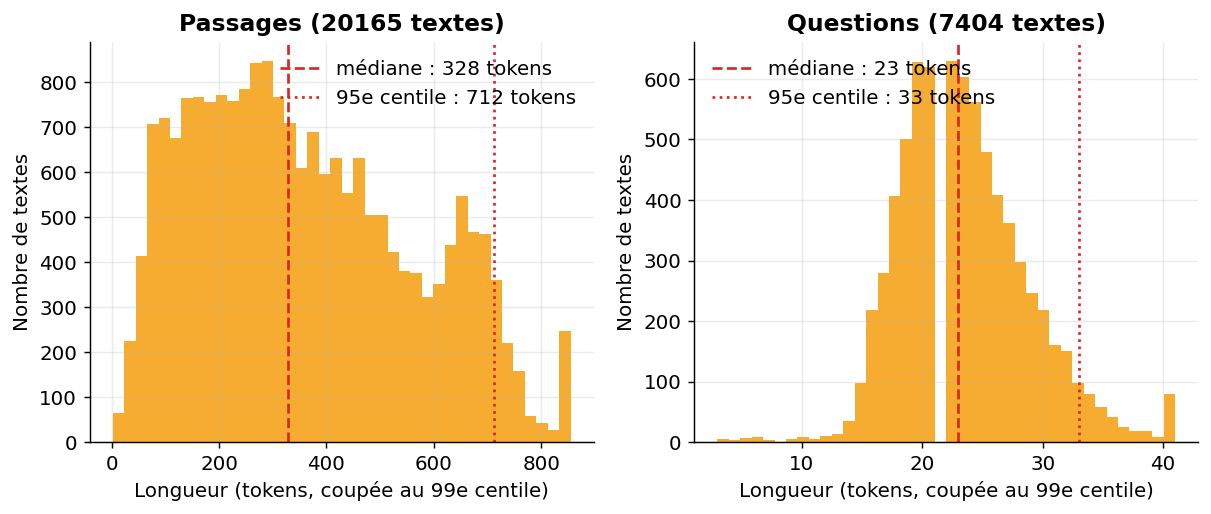

*Figure — Longueur en tokens des passages (à gauche) et des questions (à droite), tous jeux confondus. Les traits verticaux marquent la médiane et le 95e centile : la longueur maximale retenue doit couvrir au moins 95 % des textes.*

In [13]:
if PHASE == "public":
    length_table = collect_lengths(train_pairs, all_sets)
    plot_lengths(length_table)
    preview(train_pairs)
    sample_queries = list(main_set.queries.items())[:5]
    preview(pd.DataFrame(sample_queries, columns=["query_id", "question"]))

### Données internes : colonnes attendues et jeu factice
Le jeu interne contient une ligne par couple (requête, passage jugé), avec une **pertinence de 0 à 3**. Pour vérifier que tout le code tourne sans donnée réelle, `make_fake_data` produit un jeu **entièrement fictif** sur des opérations courantes (carte de paiement, virement, compte, prélèvement). Chaque procédure y existe en plusieurs versions datées.

In [14]:
PRIVATE_COLUMNS = {
    "query": "Question d'un utilisateur métier.",
    "passage_id": "Identifiant du passage ou document.",
    "passage_text": "Texte du passage.",
    "relevance": "Jugement de pertinence (0 à 3) requête/passage.",
    "document_date": "Date de version du document.",
}
EVAL_PASSAGE_SHARE = 0.3  # part des passages réservée à l'évaluation (découpage par passage)
TRAIN_MIN_RELEVANCE = 2  # seuls les jugements forts deviennent des paires d'entraînement

FAKE_TOPICS = {
    "carte de paiement": ["le plafond de paiement", "la mise en opposition", "le paiement sans contact", "les retraits à l'étranger"],
    "virement": ["le virement instantané", "le délai d'exécution", "l'ajout d'un bénéficiaire", "le virement permanent"],
    "compte": ["l'ouverture en ligne", "la clôture", "le relevé mensuel", "le découvert autorisé"],
    "prélèvement": ["le mandat de prélèvement", "la contestation", "l'échéancier", "la révocation"],
}
FAKE_QUESTIONS = [
    "Comment fonctionne {aspect} ({topic}) pour un montant de {amount} euros ?",
    "Quelles sont les conditions pour {aspect} ({topic}) au-delà de {amount} euros ?",
    "Quel est le délai pour {aspect} ({topic}) sous {days} jours ?",
    "Que faire si {aspect} ({topic}) pose problème depuis {days} jours ?",
]
FAKE_FILLER = [
    "La demande est traitée par le service client sous réserve de vérification.",
    "Des frais peuvent s'appliquer selon la grille tarifaire en vigueur.",
    "Un justificatif d'identité peut être demandé.",
    "Le client reçoit une confirmation par message sécurisé.",
    "Les conditions générales précisent les cas d'exclusion.",
    "Le conseiller peut ajuster le plafond après étude du dossier.",
    "L'opération apparaît dans l'historique sous 24 heures.",
    "En cas de litige, une réclamation écrite est possible.",
]

### Générateur du jeu factice
Pour chaque requête fictive, on juge quatre passages : la bonne procédure (3), une autre version du même aspect (2), le même thème avec un autre aspect (1) et un autre thème (0). Les lignes sont ensuite **mélangées**, parce que le code ne doit dépendre d'aucun ordre.

In [15]:
def fake_passages(rng: np.random.Generator, versions: int = 12) -> list[dict]:
    """Passages fictifs de procédures : plusieurs versions datées par thème et par aspect."""
    passages = []
    for topic_index, (topic, aspects) in enumerate(FAKE_TOPICS.items()):
        for aspect_index, aspect in enumerate(aspects):
            for version in range(versions):
                filler = " ".join(rng.choice(FAKE_FILLER, size=int(rng.integers(2, 7)), replace=False))
                text = (f"Procédure {topic} : {aspect}. Montant de référence : {int(rng.integers(50, 5000))} euros, "
                        f"délai de traitement : {int(rng.integers(1, 30))} jours ouvrés. {filler}")
                date = pd.Timestamp("2021-01-01") + pd.Timedelta(days=int(rng.integers(0, 2000)))
                passages.append({"passage_id": f"PROC-{topic_index}{aspect_index}-{version:02d}", "topic": topic,
                                 "aspect": aspect, "text": text, "date": date.strftime("%Y-%m-%d")})
    return passages


def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice de n lignes (requête, passage jugé, pertinence 0 à 3, date), dans un ordre mélangé."""
    rng = np.random.default_rng(SEED)
    passages = fake_passages(rng)
    rows = []
    for _ in range(max(1, n // 4)):
        target = passages[int(rng.integers(len(passages)))]
        question = str(rng.choice(FAKE_QUESTIONS)).format(aspect=target["aspect"], topic=target["topic"],
                                                          amount=int(rng.integers(100, 9000)), days=int(rng.integers(2, 60)))
        pools = [([target], 3),
                 ([p for p in passages if p["aspect"] == target["aspect"] and p is not target], 2),
                 ([p for p in passages if p["topic"] == target["topic"] and p["aspect"] != target["aspect"]], 1),
                 ([p for p in passages if p["topic"] != target["topic"]], 0)]
        for pool, relevance in pools:
            passage = pool[int(rng.integers(len(pool)))]
            rows.append({"query": question, "passage_id": passage["passage_id"], "passage_text": passage["text"],
                         "relevance": relevance, "document_date": passage["date"]})
    return pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)

### Types explicites
Le jeu est relu depuis un fichier, CSV compris : chaque colonne est donc convertie explicitement (texte, nombre, date). Les lignes sans pertinence lisible ou sans texte sont retirées, et la pertinence est bornée entre 0 et 3.

In [16]:
def clean_private_frame(frame: pd.DataFrame) -> pd.DataFrame:
    """Convertit explicitement les types et retire les lignes inutilisables."""
    frame = frame.copy()
    for column in ["query", "passage_id", "passage_text"]:
        frame[column] = frame[column].astype(str).str.strip()
    frame["relevance"] = pd.to_numeric(frame["relevance"], errors="coerce")
    frame["document_date"] = pd.to_datetime(frame["document_date"], errors="coerce")
    frame = frame.dropna(subset=["relevance"])
    frame = frame[(frame["query"] != "") & (frame["passage_text"] != "") & (frame["passage_id"] != "")].copy()
    frame["relevance"] = frame["relevance"].clip(0, 3).astype(int)
    frame["query_id"] = frame["query"].map(lambda text: stable_id(text, "q"))
    return frame.reset_index(drop=True)

### Découpage sans fuite
- **Version courante** : pour chaque passage, on garde le texte de la date la plus récente.
- **Découpage par passage** (identifiant de passage ou de document) : un passage sert soit à l'entraînement, soit à l'évaluation, jamais aux deux.
- Une requête d'évaluation ne sert pas à l'entraînement. Les paires d'entraînement viennent des jugements forts (≥ 2).
- Ensuite viennent les mêmes transformations qu'en phase publique : échantillonnage et mise au format `RetrievalSet`.

In [17]:
def build_private_sets(frame: pd.DataFrame) -> tuple[pd.DataFrame, RetrievalSet]:
    """Construit les paires d'entraînement et le jeu d'évaluation, découpés par passage."""
    frame = clean_private_frame(frame)
    latest_text = frame.sort_values("document_date", na_position="first").groupby("passage_id")["passage_text"].last()
    shuffled = np.random.default_rng(SEED).permutation(np.array(sorted(latest_text.index)))
    eval_ids = {str(p) for p in shuffled[: max(1, int(round(EVAL_PASSAGE_SHARE * len(shuffled))))]}
    judged = frame[(frame["relevance"] > 0) & frame["passage_id"].isin(eval_ids)]
    qrels = {}
    for query_id, passage_id, relevance in zip(judged["query_id"], judged["passage_id"], judged["relevance"]):
        previous = qrels.get(query_id, {}).get(passage_id, 0)
        qrels.setdefault(query_id, {})[passage_id] = max(int(relevance), previous)
    query_texts = dict(zip(frame["query_id"], frame["query"]))
    eval_full = RetrievalSet("Données internes (évaluation)", {q: query_texts[q] for q in qrels},
                             {p: latest_text[p] for p in sorted(eval_ids)}, qrels)
    # Entraînement : autres passages, autres requêtes, jugements forts uniquement
    train_rows = frame[(frame["relevance"] >= TRAIN_MIN_RELEVANCE) & ~frame["passage_id"].isin(eval_ids)
                       & ~frame["query_id"].isin(set(qrels))]
    train_frame = pd.DataFrame({"question": train_rows["query"].to_numpy(),
                                "context": train_rows["passage_id"].map(latest_text).to_numpy()}).drop_duplicates()
    return sample_pairs(train_frame), subsample_set(eval_full, N_EVAL_QUERIES, N_CORPUS_DOCS, SEED)

### Chargement (phase interne)
Les données sont lues par `load_private_data`, avec la correspondance de colonnes de la configuration. On affiche seulement des effectifs et la structure, jamais de contenu. Les jeux publics NanoBEIR-fr ne sont pas utilisés dans l'environnement cible.

In [18]:
if PHASE == "private":
    private_frame = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=1600)
    print(f"Lignes lues : {len(private_frame)} · requêtes distinctes : {private_frame['query'].nunique()}")
    display(pd.to_numeric(private_frame["relevance"], errors="coerce").value_counts().sort_index()
            .rename("lignes par niveau de pertinence").to_frame())
    train_pairs, main_set = build_private_sets(private_frame)
    nanobeir_sets = {}  # pas de jeu public dans l'environnement cible
    all_sets = {"main": main_set}
    display(pd.DataFrame([describe_set(main_set)]))
    print(f"Paires d'entraînement : {len(train_pairs)}")
    length_table = collect_lengths(train_pairs, all_sets)
    plot_lengths(length_table)
    preview(train_pairs)

## 3. L'approche de référence

### Réglages d'entraînement communs
Les deux modèles utilisent **exactement** les mêmes réglages. Seule la perte diffère.
- **Négatifs dans le lot** : pour une question, les autres passages du lot servent d'exemples faux. Un lot plus grand donne une tâche plus difficile.
- Un taux d'apprentissage plus élevé pour la projection 768 → 128, qui part de zéro.
- Un budget de temps borne chaque entraînement, et le relevé de progression est régulier.

In [19]:
DEVICE = device()
USE_FP16 = DEVICE == "cuda"  # précision mixte seulement sur GPU NVIDIA
AUTOCAST_DEVICE = "cuda" if USE_FP16 else "cpu"
PROJECTION_DIM = 128  # dimension de chaque vecteur de token, comme la source
DOC_LENGTH_CAP = by_scale(reduced=128, full=384)  # plafond de longueur des passages (tokens)
QUERY_LENGTH_CAP = by_scale(reduced=64, full=256)  # plafond de longueur des requêtes (tokens)
BATCH_SIZE = by_scale(reduced=16, full=32)  # paires par lot : les autres passages servent de négatifs
ENCODE_BATCH_SIZE = by_scale(reduced=16, full=64)  # taille des lots d'encodage à l'évaluation
EPOCHS = 1  # une époque, comme la source
LEARNING_RATE = 3e-5  # encodeur pré-entraîné : petit pas classique de fine-tuning
PROJECTION_LEARNING_RATE = 3e-4  # projection initialisée au hasard : pas plus grand
WARMUP_RATIO = 0.1  # 10 % des pas en montée progressive du taux
WEIGHT_DECAY = 0.01  # régularisation légère d'AdamW
TRAIN_POOL_FACTOR = 4  # facteur de fusion vu à l'entraînement par la nouvelle approche
MAX_TRAIN_SECONDS = by_scale(reduced=420, full=1200)  # budget de temps par entraînement (s)
LOG_EVERY = by_scale(reduced=5, full=25)  # fréquence du relevé de progression (pas)
APPROACH_NAMES = {"reference": "Multi-vecteur entraîné normalement",
                  "new": "Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss"}
set_seed(SEED)
print(f"Appareil : {DEVICE} · précision mixte : {USE_FP16} · transformers {transformers.__version__}")

Appareil : cuda · précision mixte : True · transformers 5.22.1


### Choisir la longueur maximale à partir des données
On prend le plus petit multiple de 16 qui couvre **95 % des textes**, sans dépasser le plafond fixé par le budget de mémoire et de temps. Le tableau donne la **part de textes coupés** pour chaque source. Au-delà de 5 %, la cellule l'affiche explicitement.

In [20]:
def choose_length(lengths: pd.Series, cap: int) -> int:
    """Plus petit multiple de 16 couvrant 95 % des textes, borné par `cap`."""
    return int(min(cap, 16 * math.ceil(lengths.quantile(0.95) / 16)))


MAX_DOC_LENGTH = choose_length(length_table.loc[length_table["kind"] == "passage", "tokens"], DOC_LENGTH_CAP)
MAX_QUERY_LENGTH = choose_length(length_table.loc[length_table["kind"] == "question", "tokens"], QUERY_LENGTH_CAP)
limits = np.where(length_table["kind"] == "passage", MAX_DOC_LENGTH, MAX_QUERY_LENGTH)
truncated_share = (length_table.assign(truncated=length_table["tokens"] > limits)
                   .groupby(["kind", "source"])["truncated"].mean().mul(100).round(1)
                   .rename("part tronquée (%)").to_frame())
print(f"Longueur maximale : passages {MAX_DOC_LENGTH} tokens, requêtes {MAX_QUERY_LENGTH} tokens")
display(truncated_share)
over = truncated_share[truncated_share["part tronquée (%)"] > 5]
if len(over):
    print("Plus de 5 % de textes coupés pour :", ", ".join(f"{kind} / {source}" for kind, source in over.index),
          f"— plafond imposé par le budget de mémoire et de temps ({DOC_LENGTH_CAP} tokens pour les passages).")
assert len(main_set.queries) >= MIN_EVAL_QUERIES, "Moins de 100 requêtes d'évaluation : expérience non concluante"
assert len(train_pairs) >= 2 * BATCH_SIZE, "Trop peu de paires d'entraînement"

Longueur maximale : passages 384 tokens, requêtes 48 tokens


part tronquée (%)
kind     source                         
passage  NanoArguAna                12.8
         NanoFiQA2018               15.9
         NanoNFCorpus               57.9
         NanoSciFact                43.9
         entraînement               68.5
         main                       65.0
question NanoArguAna               100.0
         NanoFiQA2018                0.0
         NanoNFCorpus                0.0
         NanoSciFact                 6.0
         entraînement                0.0
         main                        0.0

Plus de 5 % de textes coupés pour : passage / NanoArguAna, passage / NanoFiQA2018, passage / NanoNFCorpus, passage / NanoSciFact, passage / entraînement, passage / main, question / NanoArguAna, question / NanoSciFact — plafond imposé par le budget de mémoire et de temps (384 tokens pour les passages).


### L'encodeur multi-vecteur
On place une **projection linéaire** de 768 à 128 dimensions sur ModernCamemBERT, puis une **normalisation** : chaque token devient un vecteur unitaire, et le produit scalaire de deux vecteurs est leur similarité cosinus.
- Les poids sont gardés en float32 : sur GPU, la précision mixte (autocast) se charge du float16.
- La compilation automatique propre à ModernBERT est désactivée, pour que le calcul soit le même sur CPU et sur GPU.
- `attention_implementation` relève le calcul d'attention réellement utilisé, consigné avec les résultats.

In [21]:
class MultiVectorEncoder(torch.nn.Module):
    """Encodeur de type ColBERT : un vecteur normalisé de PROJECTION_DIM dimensions par token."""

    def __init__(self) -> None:
        """Charge ModernCamemBERT (révision épinglée, float32) et crée la projection vers PROJECTION_DIM."""
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_SOURCE, revision=MODEL_REVISION_USED).float()
        if hasattr(self.encoder.config, "reference_compile"):
            self.encoder.config.reference_compile = False  # même chemin de calcul partout
        self.projection = torch.nn.Linear(self.encoder.config.hidden_size, PROJECTION_DIM, bias=False)

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        """Rend un vecteur unitaire par token : tenseur [lot, tokens, PROJECTION_DIM]."""
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return F.normalize(self.projection(hidden), dim=-1)

    def encode(self, texts: list[str], max_length: int) -> tuple[torch.Tensor, torch.Tensor]:
        """Tokenise et encode des textes ; rend (vecteurs [lot, tokens, dim], masque des vrais tokens)."""
        batch = tokenizer(texts, padding=True, truncation=True, max_length=max_length, return_tensors="pt")
        input_ids, attention_mask = batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE)
        return self(input_ids, attention_mask), attention_mask.bool()


def attention_implementation(model: MultiVectorEncoder) -> str:
    """Implémentation d'attention réellement utilisée (sdpa, eager…), consignée avec les résultats."""
    return str(getattr(model.encoder.config, "_attn_implementation", "inconnue"))

### Encoder un jeu entier
À l'évaluation, les textes sont triés par longueur pour limiter le rembourrage (*padding*). Chaque texte devient une matrice (tokens × 128) en float16, ce qui divise la mémoire par deux. Sur le jeu principal, les requêtes sont encodées **une par une** et chronométrées : c'est la première partie de la latence d'une recherche.

In [22]:
@torch.no_grad()
def encode_texts(model: MultiVectorEncoder, texts: list[str], max_length: int) -> list[np.ndarray]:
    """Encode des textes par lots triés par longueur ; rend une matrice (tokens, dim) float16 par texte."""
    model.eval()
    order = np.argsort([len(text) for text in texts], kind="stable")
    vectors: list = [None] * len(texts)
    for start in range(0, len(texts), ENCODE_BATCH_SIZE):
        rows = order[start:start + ENCODE_BATCH_SIZE]
        with torch.autocast(device_type=AUTOCAST_DEVICE, dtype=torch.float16, enabled=USE_FP16):
            embeddings, mask = model.encode([texts[i] for i in rows], max_length)
        embeddings, mask = embeddings.float().cpu().numpy(), mask.cpu().numpy()
        for position, row in enumerate(rows):
            vectors[row] = embeddings[position][mask[position]].astype(np.float16)
    return vectors


def encode_all_sets(model: MultiVectorEncoder) -> dict:
    """Encode requêtes et passages de chaque jeu ; requêtes du jeu principal une à une, chronométrées."""
    encoded = {}
    for set_key, rset in all_sets.items():
        query_texts, query_ms = list(rset.queries.values()), []
        if set_key == "main":
            encode_texts(model, query_texts[:1], MAX_QUERY_LENGTH)  # échauffement hors chronométrage
            query_vectors = []
            for text in query_texts:
                with timer(query_ms):
                    query_vectors.extend(encode_texts(model, [text], MAX_QUERY_LENGTH))
        else:
            query_vectors = encode_texts(model, query_texts, MAX_QUERY_LENGTH)
        doc_vectors = encode_texts(model, list(rset.corpus.values()), MAX_DOC_LENGTH)
        encoded[set_key] = {"queries": query_vectors, "docs": doc_vectors, "query_ms": query_ms}
    return encoded

### Le token pooling (Ward)
Pour un passage de $n$ vecteurs, on construit l'arbre de **Ward**, qui fusionne pas à pas les deux groupes dont la réunion augmente le moins la dispersion. On le coupe ensuite en $k = \lceil n / \text{pool\_factor} \rceil$ groupes, ou en $k$ = `max_tokens`. Chaque groupe est remplacé par sa **moyenne normalisée**.
- L'affectation aux groupes est calculée **sans gradient**, sur des copies détachées.
- La moyenne reste dérivable : le gradient revient aux tokens d'origine.
- Les mêmes fonctions servent à l'entraînement et à l'évaluation.

In [23]:
def n_clusters_for(n_tokens: int, pool_factor: int | None = None, max_tokens: int | None = None) -> int:
    """Nombre de groupes visé : ceil(n / pool_factor) ou max_tokens, borné entre 1 et n."""
    target = math.ceil(n_tokens / pool_factor) if pool_factor is not None else int(max_tokens)
    return max(1, min(n_tokens, target))


def ward_tree(vectors: np.ndarray):
    """Arbre de Ward d'un passage (None s'il n'a qu'un vecteur) ; calculé une fois, coupé à plusieurs niveaux."""
    return linkage(vectors.astype(np.float64), method="ward") if len(vectors) > 1 else None


def ward_labels(tree, n_tokens: int, n_clusters: int) -> np.ndarray:
    """Coupe l'arbre en `n_clusters` groupes ; étiquettes 0..k-1 (identité s'il n'y a rien à fusionner)."""
    if tree is None or n_clusters >= n_tokens:
        return np.arange(n_tokens)
    return np.unique(fcluster(tree, t=n_clusters, criterion="maxclust"), return_inverse=True)[1].reshape(-1)


def pool_tensor(vectors: torch.Tensor, labels: np.ndarray) -> torch.Tensor:
    """Moyenne normalisée de chaque groupe, dérivable par rapport aux vecteurs d'origine."""
    index = torch.as_tensor(labels, device=vectors.device, dtype=torch.long)
    n_groups = int(index.max()) + 1
    sums = torch.zeros(n_groups, vectors.shape[1], device=vectors.device, dtype=vectors.dtype).index_add(0, index, vectors)
    counts = torch.bincount(index, minlength=n_groups).clamp(min=1).to(vectors.dtype)
    return F.normalize(sums / counts[:, None], dim=-1)


def pool_batch(doc_embeddings: torch.Tensor, doc_mask: torch.Tensor, pool_factor: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Fusionne les vecteurs de chaque passage du lot ; rend un lot rembourré et son masque."""
    pooled = []
    for row in range(doc_embeddings.shape[0]):
        vectors = doc_embeddings[row][doc_mask[row]]
        tree = ward_tree(vectors.detach().float().cpu().numpy())  # affectation discrète, hors gradient
        pooled.append(pool_tensor(vectors, ward_labels(tree, len(vectors), n_clusters_for(len(vectors), pool_factor))))
    padded = torch.nn.utils.rnn.pad_sequence(pooled, batch_first=True)
    lengths = torch.tensor([len(p) for p in pooled], device=padded.device)
    return padded, torch.arange(padded.shape[1], device=padded.device)[None, :] < lengths[:, None]

### Score MaxSim et perte de recherche
- **MaxSim** : $s(q, d) = \sum_i \max_j\, q_i^\top d_j$. Chaque token de la requête prend son meilleur vecteur du passage.
- **Perte à négatifs dans le lot** : une entropie croisée qui pousse le bon passage en tête parmi ceux du lot. Quand deux paires partagent le même passage, le doublon est masqué, sinon il compterait à tort comme faux.
- `compute_loss` contient les deux variantes : `standard` pour la référence, et `pooling_aware` (perte standard et perte après fusion, à parts égales) pour la nouvelle approche.

In [24]:
def maxsim_scores(query_emb: torch.Tensor, query_mask: torch.Tensor,
                  doc_emb: torch.Tensor, doc_mask: torch.Tensor) -> torch.Tensor:
    """Score MaxSim de chaque requête contre chaque passage du lot : matrice (requêtes, passages)."""
    similarity = torch.einsum("ash,bth->abst", query_emb, doc_emb)
    similarity = similarity.masked_fill(~doc_mask[None, :, None, :], -1e4)  # ignore le rembourrage
    best = similarity.amax(dim=3) * query_mask[:, None, :].to(similarity.dtype)
    return best.sum(dim=2).float()


def duplicate_mask(passages: list[str], device) -> torch.Tensor:
    """Vrai quand deux paires du lot partagent le même passage (faux négatif à masquer)."""
    codes = torch.as_tensor(pd.factorize(pd.Series(passages))[0], device=device)
    same = codes[:, None] == codes[None, :]
    return same & ~torch.eye(len(passages), dtype=torch.bool, device=device)


def in_batch_loss(scores: torch.Tensor, false_negatives: torch.Tensor) -> torch.Tensor:
    """Entropie croisée : le passage de chaque question doit sortir premier parmi ceux du lot."""
    scores = scores.masked_fill(false_negatives, -1e4)
    return F.cross_entropy(scores, torch.arange(scores.shape[0], device=scores.device))


def compute_loss(model: MultiVectorEncoder, batch: pd.DataFrame, loss_kind: str) -> torch.Tensor:
    """Perte d'un lot : standard, ou moyenne de la perte standard et de la perte après fusion (pooling_aware)."""
    passages = batch["context"].tolist()
    query_emb, query_mask = model.encode(batch["question"].tolist(), MAX_QUERY_LENGTH)
    doc_emb, doc_mask = model.encode(passages, MAX_DOC_LENGTH)
    false_negatives = duplicate_mask(passages, query_emb.device)
    loss = in_batch_loss(maxsim_scores(query_emb, query_mask, doc_emb, doc_mask), false_negatives)
    if loss_kind == "pooling_aware":
        pooled_emb, pooled_mask = pool_batch(doc_emb, doc_mask, TRAIN_POOL_FACTOR)
        pooled_loss = in_batch_loss(maxsim_scores(query_emb, query_mask, pooled_emb, pooled_mask), false_negatives)
        loss = 0.5 * loss + 0.5 * pooled_loss  # parts égales, comme la source
    return loss

### Lots identiques et libération de la mémoire
L'ordre des lots est fixé par la graine. Les deux modèles voient donc **les mêmes paires, dans le même ordre**. Entre deux approches, on libère la mémoire (ramasse-miettes, puis cache du GPU s'il y en a un).

In [25]:
def make_batches(n_rows: int) -> list[np.ndarray]:
    """Lots d'indices dans un ordre fixé par la graine, identiques pour les deux modèles."""
    batches = []
    for epoch in range(EPOCHS):
        order = np.random.default_rng(SEED + epoch).permutation(n_rows)
        batches += [order[i:i + BATCH_SIZE] for i in range(0, n_rows, BATCH_SIZE)]
    return [batch for batch in batches if len(batch) >= 2]  # un lot d'une paire n'a pas de négatif


def free_memory() -> None:
    """Libère la mémoire entre deux approches (CPU, puis GPU s'il y en a un)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### La boucle d'entraînement
C'est une boucle classique : AdamW, montée progressive puis décroissance linéaire du taux, écrêtage des gradients à 1, et précision mixte sur GPU. Elle sert aux deux approches.
- `max_steps` permet d'imposer à la nouvelle approche **le même nombre de pas** que la référence.
- Si le budget de temps est dépassé, l'arrêt est propre et noté dans le journal.

In [26]:
def train_model(loss_kind: str, max_steps: int | None = None) -> tuple[MultiVectorEncoder, dict]:
    """Entraîne un encodeur avec la perte demandée (`standard` ou `pooling_aware`) ; rend le modèle et le journal."""
    assert loss_kind in {"standard", "pooling_aware"}
    set_seed(SEED)  # même initialisation de la projection pour les deux modèles
    model = MultiVectorEncoder().to(DEVICE)
    optimizer = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": LEARNING_RATE},
                                   {"params": model.projection.parameters(), "lr": PROJECTION_LEARNING_RATE}],
                                  weight_decay=WEIGHT_DECAY)
    batches = make_batches(len(train_pairs))[:max_steps]
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * len(batches)), len(batches))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    log = {"loss_kind": loss_kind, "losses": [], "stopped_early": False}
    start = time.perf_counter()
    model.train()
    for step, rows in enumerate(batches):
        if time.perf_counter() - start > MAX_TRAIN_SECONDS:
            log["stopped_early"] = True
            break
        with torch.autocast(device_type=AUTOCAST_DEVICE, dtype=torch.float16, enabled=USE_FP16):
            loss = compute_loss(model, train_pairs.iloc[rows], loss_kind)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        log["losses"].append(float(loss.detach()))
        if step % LOG_EVERY == 0 or step == len(batches) - 1:
            recent = np.mean(log["losses"][-LOG_EVERY:])
            print(f"[{loss_kind}] pas {step + 1}/{len(batches)} · perte {recent:.3f} · {time.perf_counter() - start:.0f} s")
    log.update(steps=len(log["losses"]), planned_steps=len(batches), seconds=time.perf_counter() - start)
    return model, log

### Contrôle sur un exemple réel
Avant toute mesure, on encode une vraie requête, son passage pertinent et un autre passage. On vérifie les formes et l'absence de valeurs non finies, et on affiche **le modèle réellement évalué** (base, révision, implémentation d'attention). Après un entraînement réussi, le passage pertinent devrait en général obtenir le meilleur score.

In [27]:
def check_model(model: MultiVectorEncoder, label: str) -> None:
    """Contrôle sur un exemple réel : formes, valeurs finies, score du passage pertinent contre un autre."""
    query_id = next(iter(main_set.qrels))
    relevant_id = next(iter(main_set.qrels[query_id]))
    other_id = next(doc_id for doc_id in main_set.corpus if doc_id not in main_set.qrels[query_id])
    query = encode_texts(model, [main_set.queries[query_id]], MAX_QUERY_LENGTH)[0].astype(np.float32)
    docs = encode_texts(model, [main_set.corpus[relevant_id], main_set.corpus[other_id]], MAX_DOC_LENGTH)
    scores = [float((query @ doc.astype(np.float32).T).max(axis=1).sum()) for doc in docs]
    assert query.shape[1] == PROJECTION_DIM and np.all(np.isfinite(scores))
    print(f"Modèle évalué : {label} · base {MODEL_ID} (révision {MODEL_REVISION[:8]}) · attention {attention_implementation(model)}")
    print(f"  MaxSim passage pertinent = {scores[0]:.2f} · autre passage = {scores[1]:.2f}")

### Entraîner et encoder la référence
La référence est entraînée avec la perte standard, contrôlée sur un exemple, puis elle encode tous les jeux. On ne garde que ses vecteurs, et le modèle est libéré pour laisser la mémoire au suivant. La compression par token pooling n'intervient qu'à l'évaluation : elle est appliquée **après coup**.

In [28]:
reference_model, reference_log = train_model("standard")
check_model(reference_model, APPROACH_NAMES["reference"])
RUN_INFO = {"attention": attention_implementation(reference_model), "transformers": transformers.__version__,
            "torch": torch.__version__, "device": DEVICE, "fp16": USE_FP16}
reference_encoded = encode_all_sets(reference_model)
del reference_model
free_memory()
stopped = " (arrêt au budget de temps)" if reference_log["stopped_early"] else ""
print(f"Référence : {reference_log['steps']} pas en {reference_log['seconds']:.0f} s{stopped}")

/tmp/ipykernel_453/2797277552.py:26: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[standard] pas 1/188 · perte 2.972 · 2 s


[standard] pas 26/188 · perte 1.970 · 32 s


[standard] pas 51/188 · perte 0.860 · 63 s


[standard] pas 76/188 · perte 0.682 · 96 s


[standard] pas 101/188 · perte 0.594 · 128 s


[standard] pas 126/188 · perte 0.518 · 160 s


[standard] pas 151/188 · perte 0.484 · 192 s


[standard] pas 176/188 · perte 0.466 · 224 s


[standard] pas 188/188 · perte 0.437 · 238 s
Modèle évalué : Multi-vecteur entraîné normalement · base almanach/moderncamembert-base (révision 8e700022) · attention sdpa
  MaxSim passage pertinent = 20.91 · autre passage = 11.26


Référence : 188 pas en 238 s


## 4. La nouvelle approche

### Ce qui est repris de la source, et les écarts
On reprend l'objectif de `MultiVectorTokenPoolingLoss` tel que le décrivent le billet de blog et les notes de version 6.3.0 (section « Token pooling-aware training ») :
- une perte de recherche sur les vecteurs d'origine **et** une perte sur les vecteurs fusionnés par Ward à **pool_factor=4**, moyennées à **parts égales** ;
- le regroupement est figé (non dérivable), et le gradient revient aux tokens d'origine à travers la moyenne de chaque groupe ;
- seuls les passages sont fusionnés, jamais les requêtes.

**Écarts assumés** :
- La perte est réimplémentée en PyTorch, à côté de la classe de la bibliothèque, pour contrôler exactement le calcul. La cellule suivante relève seulement la version installée.
- Le clustering de Ward est calculé par SciPy, sans le noyau CUDA de la bibliothèque. Le résultat est le même, seul le temps change.
- On entraîne sur des paires avec négatifs dans le lot, et non sur des triplets avec un négatif difficile.
- Le modèle de base est ModernCamemBERT (français), et non ModernBERT (anglais).

In [29]:
import importlib
import pkgutil

SOURCE_CLASS_NAMES = ["MultiVectorTokenPoolingLoss", "MultiVectorEncoder"]  # classes citées par la source


def find_library_classes(names: list[str]) -> pd.DataFrame:
    """Relevé informatif : version de sentence-transformers et module qui expose chaque classe citée."""
    try:
        import sentence_transformers
    except Exception as error:  # le relevé ne conditionne pas l'expérience
        return pd.DataFrame({"classe": names, "module": f"bibliothèque non importable ({type(error).__name__})"})
    found = {name: "absente" for name in names}
    for info in pkgutil.walk_packages(sentence_transformers.__path__, "sentence_transformers.", onerror=lambda _: None):
        if not any(word in info.name for word in ("multi", "loss", "pool")):
            continue
        try:
            module = importlib.import_module(info.name)
        except Exception:  # module optionnel dont une dépendance manque
            continue
        for name in names:
            if found[name] == "absente" and hasattr(module, name):
                found[name] = info.name
    print(f"sentence-transformers {sentence_transformers.__version__}")
    return pd.DataFrame({"classe": list(found), "module": list(found.values())})


display(find_library_classes(SOURCE_CLASS_NAMES))

sentence-transformers 6.3.0


,classe,module
0,MultiVectorTokenPoolingLoss,sentence_transformers.multi_vector_encoder.losses
1,MultiVectorEncoder,sentence_transformers.multi_vector_encoder


### Entraîner et encoder la nouvelle approche
Tout est identique à la référence : même initialisation, mêmes lots, même nombre de pas (`max_steps`). Seule la perte change (`pooling_aware`). Un `assert` vérifie que les deux modèles ont fait le même nombre de pas. Les pertes ne se comparent pas directement d'un modèle à l'autre, car celle de la nouvelle approche est une moyenne de deux termes.

In [30]:
new_model, new_log = train_model("pooling_aware", max_steps=reference_log["steps"])
check_model(new_model, APPROACH_NAMES["new"])
new_encoded = encode_all_sets(new_model)
del new_model
free_memory()
training_summary = pd.DataFrame([
    {"approche": APPROACH_NAMES[key], "pas": log["steps"], "durée (s)": round(log["seconds"]),
     "perte moyenne des 5 derniers pas": round(float(np.mean(log["losses"][-5:])), 3), "arrêt au budget": log["stopped_early"]}
    for key, log in [("reference", reference_log), ("new", new_log)]])
display(training_summary)
assert new_log["steps"] == reference_log["steps"], "Les deux modèles doivent voir exactement les mêmes lots"

/tmp/ipykernel_453/2797277552.py:26: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[pooling_aware] pas 1/188 · perte 3.056 · 2 s


[pooling_aware] pas 26/188 · perte 2.007 · 41 s


[pooling_aware] pas 51/188 · perte 0.862 · 79 s


[pooling_aware] pas 76/188 · perte 0.690 · 118 s


[pooling_aware] pas 101/188 · perte 0.592 · 157 s


[pooling_aware] pas 126/188 · perte 0.527 · 195 s


[pooling_aware] pas 151/188 · perte 0.481 · 234 s


[pooling_aware] pas 176/188 · perte 0.463 · 272 s


[pooling_aware] pas 188/188 · perte 0.434 · 290 s
Modèle évalué : Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss · base almanach/moderncamembert-base (révision 8e700022) · attention sdpa
  MaxSim passage pertinent = 20.83 · autre passage = 11.46


,approche,pas,durée (s),perte moyenne des 5 derniers pas,arrêt au budget
0,Multi-vecteur entraîné normalement,188,238,0.433,False
1,Multi-vecteur entraîné avec MultiVectorTokenPo...,188,290,0.422,False


## 5. Évaluation

### Réglages de compression et métriques de classement
Chaque modèle est évalué sans fusion, à pool_factor 2 et 4, puis avec 4 vecteurs au plus par passage (`max_tokens=4`).
- **nDCG@10** (en points, de 0 à 100) : récompense les passages pertinents placés haut dans les 10 premiers, avec des gains gradués.
- **Rappel@100** : part des passages pertinents retrouvés dans les 100 premiers.
- **Plancher aléatoire** : nDCG@10 d'un classement tiré au hasard. Un modèle qui ne le dépasse pas n'a rien appris.

In [31]:
POOL_CONFIGS = {
    "sans fusion": {"pool_factor": 1},
    "pool_factor=2": {"pool_factor": 2},
    "pool_factor=4": {"pool_factor": 4},
    "max_tokens=4": {"max_tokens": 4},
}
TOP_K = 100  # profondeur du classement conservé (rappel@100)
SEARCH_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32  # float16 lent sur CPU
BYTES_PER_VALUE = 2  # index supposé stocké en float16


def ndcg_at_k(ranked: list[str], qrel: dict[str, int], k: int = 10) -> float:
    """nDCG@k avec gains gradués (pertinence brute), entre 0 et 1."""
    dcg = sum(qrel.get(doc_id, 0) / math.log2(rank + 2) for rank, doc_id in enumerate(ranked[:k]))
    ideal = sorted(qrel.values(), reverse=True)[:k]
    idcg = sum(gain / math.log2(rank + 2) for rank, gain in enumerate(ideal))
    return dcg / idcg if idcg > 0 else 0.0


def recall_at_k(ranked: list[str], qrel: dict[str, int], k: int = 100) -> float:
    """Part des passages pertinents présents dans les k premiers résultats."""
    relevant = {doc_id for doc_id, gain in qrel.items() if gain > 0}
    return len(relevant & set(ranked[:k])) / len(relevant)


def first_relevant_rank(ranked: list[str], qrel: dict[str, int]) -> float:
    """Rang (à partir de 1) du premier passage pertinent, NaN s'il est au-delà de TOP_K."""
    return next((rank + 1 for rank, doc_id in enumerate(ranked) if qrel.get(doc_id, 0) > 0), np.nan)


def random_ndcg(rset: RetrievalSet, n_draws: int = 20) -> float:
    """nDCG@10 moyen (points) d'un classement tiré au hasard : plancher du prédicteur trivial."""
    rng = np.random.default_rng(SEED)
    doc_ids = np.array(list(rset.corpus))
    scores = [100 * ndcg_at_k(rng.choice(doc_ids, size=min(10, len(doc_ids)), replace=False).tolist(), qrel)
              for qrel in rset.qrels.values() for _ in range(n_draws)]
    return float(np.mean(scores))

### Index et recherche exhaustive
Les passages, éventuellement compressés, sont rangés dans un tenseur rembourré (passages × vecteurs × 128) accompagné d'un masque. Une requête est comparée à **tous** les passages par MaxSim : c'est une recherche exacte, sans index approché. Le temps de cette étape est mesuré requête par requête.

In [32]:
def build_index(doc_vectors: list[np.ndarray]) -> tuple[torch.Tensor, torch.Tensor]:
    """Range les passages dans un tenseur rembourré (passages, vecteurs, dim) et son masque."""
    max_len = max(len(vectors) for vectors in doc_vectors)
    index = torch.zeros(len(doc_vectors), max_len, PROJECTION_DIM, dtype=SEARCH_DTYPE)
    mask = torch.zeros(len(doc_vectors), max_len, dtype=torch.bool)
    for row, vectors in enumerate(doc_vectors):
        index[row, :len(vectors)] = torch.from_numpy(np.asarray(vectors, dtype=np.float32)).to(SEARCH_DTYPE)
        mask[row, :len(vectors)] = True
    return index.to(DEVICE), mask.to(DEVICE)


@torch.no_grad()
def search_index(query_vectors: np.ndarray, index: torch.Tensor, mask: torch.Tensor) -> np.ndarray:
    """Classe tous les passages par MaxSim pour une requête ; rend les indices des TOP_K premiers."""
    query = torch.as_tensor(np.asarray(query_vectors, dtype=np.float32), device=DEVICE).to(SEARCH_DTYPE)
    similarity = torch.einsum("sh,nth->nst", query, index).masked_fill(~mask[:, None, :], -1e4)
    scores = similarity.amax(dim=2).sum(dim=1).float()
    return torch.topk(scores, k=min(TOP_K, scores.shape[0])).indices.cpu().numpy()

### Évaluer un réglage de compression
Pour un modèle, un jeu et un réglage, on fusionne les passages avec les arbres de Ward déjà calculés, on construit l'index et on cherche chaque requête. On obtient des métriques **par requête**, nécessaires au bootstrap, ainsi que le nombre moyen de vecteurs par passage et la taille de l'index en float16 :
$\text{taille (Mo)} = \text{vecteurs} \times 128 \times 2\ \text{octets} / 10^6$.

In [33]:
def evaluate_config(encoded_set: dict, trees: list, rset: RetrievalSet, spec: dict) -> dict:
    """Fusionne les passages selon `spec`, cherche chaque requête et rend les métriques par requête."""
    pooled_docs = []
    for vectors, tree in zip(encoded_set["docs"], trees):
        labels = ward_labels(tree, len(vectors), n_clusters_for(len(vectors), **spec))
        pooled_docs.append(pool_tensor(torch.from_numpy(vectors.astype(np.float32)), labels).numpy())
    index, mask = build_index(pooled_docs)
    doc_ids = np.array(list(rset.corpus))
    ndcg, recall, ranks, search_ms = [], [], [], []
    for query_id, query_vectors in zip(rset.queries, encoded_set["queries"]):
        with timer(search_ms):
            top = search_index(query_vectors, index, mask)
        ranked, qrel = doc_ids[top].tolist(), rset.qrels[query_id]
        ndcg.append(100 * ndcg_at_k(ranked, qrel, 10))
        recall.append(100 * recall_at_k(ranked, qrel, TOP_K))
        ranks.append(first_relevant_rank(ranked, qrel))
    n_vectors = sum(len(doc) for doc in pooled_docs)
    del index, mask
    return {"ndcg": np.array(ndcg), "recall": np.array(recall), "first_rank": np.array(ranks, dtype=float),
            "search_ms": search_ms, "mean_vectors": n_vectors / len(pooled_docs),
            "index_mb": n_vectors * PROJECTION_DIM * BYTES_PER_VALUE / 1e6}

### Lancer l'évaluation complète
Les deux approches passent par **les mêmes requêtes, les mêmes corpus et les mêmes réglages**. Pour chaque passage, l'arbre de Ward n'est construit qu'une fois, puis on le coupe aux différents niveaux de compression.

In [34]:
def evaluate_approach(encoded: dict) -> dict:
    """Évalue un modèle sur tous les jeux et tous les réglages de fusion ; clé = (jeu, réglage)."""
    by_setting = {}
    for set_key, rset in all_sets.items():
        trees = [ward_tree(vectors) for vectors in encoded[set_key]["docs"]]
        for config_name, spec in POOL_CONFIGS.items():
            by_setting[(set_key, config_name)] = evaluate_config(encoded[set_key], trees, rset, spec)
    return by_setting


start = time.perf_counter()
ENCODED = {"reference": reference_encoded, "new": new_encoded}
evaluations = {key: evaluate_approach(encoded) for key, encoded in ENCODED.items()}
print(f"Évaluation terminée en {time.perf_counter() - start:.0f} s")

Évaluation terminée en 221 s


### Vue d'ensemble : nDCG@10 par jeu et par réglage
Le tableau croise chaque jeu, chaque réglage de compression et chaque approche. La ligne « sans fusion » donne le score de départ de chaque modèle. On peut ensuite y lire l'effet de la compression.

In [35]:
grid_rows = []
for key, by_setting in evaluations.items():
    for (set_key, config_name), measured in by_setting.items():
        grid_rows.append({"jeu": all_sets[set_key].name, "réglage": config_name, "approche": APPROACH_NAMES[key],
                          "nDCG@10": measured["ndcg"].mean(), "vecteurs par passage": measured["mean_vectors"]})
grid = pd.DataFrame(grid_rows)
display(grid.pivot_table(index=["jeu", "réglage"], columns="approche", values="nDCG@10").round(2))
display(grid.pivot_table(index=["jeu", "réglage"], values="vecteurs par passage").round(1))

approche                                     Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss  \
jeu                           réglage                                                                  
NanoBEIR-fr NanoArguAna       max_tokens=4                                               35.50         
                              pool_factor=2                                              34.07         
                              pool_factor=4                                              33.02         
                              sans fusion                                                35.39         
NanoBEIR-fr NanoFiQA2018      max_tokens=4                                               19.88         
                              pool_factor=2                                              37.22         
                              pool_factor=4                                              37.17         
                              sans fusion                                                38.08         
NanoBEIR-fr NanoNFCorpus      max_tokens=4                                               11.39         
                              pool_factor=2                                              26.98         
                              pool_factor=4                                              25.57         
                              sans fusion                                                27.01         
NanoBEIR-fr NanoSciFact       max_tokens=4                                               29.68         
                              pool_factor=2                                              58.43         
                              pool_factor=4                                              57.62         
                              sans fusion                                                60.86         
Sujet-Financial-RAG-FR (test) max_tokens=4                                               55.76         
                              pool_factor=2                                              78.17         
                              pool_factor=4                                              77.16         
                              sans fusion                                                78.61         

approche                                     Multi-vecteur entraîné normalement  
jeu                           réglage                                            
NanoBEIR-fr NanoArguAna       max_tokens=4                                36.86  
                              pool_factor=2                               33.71  
                              pool_factor=4                               32.69  
                              sans fusion                                 34.79  
NanoBEIR-fr NanoFiQA2018      max_tokens=4                                15.20  
                              pool_factor=2                               35.84  
                              pool_factor=4                               36.57  
                              sans fusion                                 36.55  
NanoBEIR-fr NanoNFCorpus      max_tokens=4                                11.34  
                              pool_factor=2                               28.42  
                              pool_factor=4                               27.03  
                              sans fusion                                 28.44  
NanoBEIR-fr NanoSciFact       max_tokens=4                                30.23  
                              pool_factor=2                               62.71  
                              pool_factor=4                               57.92  
                              sans fusion                                 64.87  
Sujet-Financial-RAG-FR (test) max_tokens=4                                53.96  
                              pool_factor=2                               78.05  
                              pool_factor=4                            

vecteurs par passage
jeu                           réglage                            
NanoBEIR-fr NanoArguAna       max_tokens=4                    4.0
                              pool_factor=2                 114.7
                              pool_factor=4                  57.6
                              sans fusion                   229.1
NanoBEIR-fr NanoFiQA2018      max_tokens=4                    4.0
                              pool_factor=2                  98.1
                              pool_factor=4                  49.2
                              sans fusion                   195.7
NanoBEIR-fr NanoNFCorpus      max_tokens=4                    4.0
                              pool_factor=2                 169.8
                              pool_factor=4                  85.0
                              sans fusion                   339.4
NanoBEIR-fr NanoSciFact       max_tokens=4                    4.0
                              pool_factor=2                 162.6
                              pool_factor=4                  81.4
                              sans fusion                   324.8
Sujet-Financial-RAG-FR (test) max_tokens=4                    4.0
                              pool_factor=2                 176.1
                              pool_factor=4                  88.2
                              sans fusion                   352.0

### Intervalles de confiance par bootstrap apparié
Le **bootstrap** consiste à retirer des requêtes au hasard, avec remise, pour voir à quel point un chiffre dépend de l'échantillon. Il est **apparié** : on tire les mêmes requêtes pour les deux termes comparés, par exemple le score compressé et le score non compressé d'un même modèle.
- **Rétention** = nDCG@10 moyen à pool_factor=4 / nDCG@10 moyen sans fusion, pour un même modèle.
- **Latence** = encodage de la requête + recherche exhaustive à pool_factor=4.

In [36]:
BOOTSTRAP_SAMPLES = 1000  # nombre de tirages du bootstrap sur les requêtes


def mean_metric(values, _paired) -> float:
    """Moyenne des scores par requête (le second argument n'existe que pour le tirage apparié)."""
    return float(np.mean(values))


def retention_metric(pooled, unpooled) -> float:
    """Rétention : nDCG moyen après fusion / nDCG moyen sans fusion du même modèle."""
    base = float(np.mean(unpooled))
    return float(np.mean(pooled)) / base if base > 0 else 0.0


def with_ci(first: np.ndarray, second: np.ndarray, metric) -> tuple[float, list[float]]:
    """Valeur et intervalle de confiance à 95 % par bootstrap apparié."""
    value, low, high = bootstrap_ci(first, second, metric, n=BOOTSTRAP_SAMPLES, seed=SEED)
    return float(value), [float(low), float(high)]


def latency_summary(durations_ms: list[float]) -> dict:
    """p50 et p95 des latences, en millisecondes, sous forme de flottants Python."""
    stats = latency_stats(durations_ms)
    if isinstance(stats, dict):
        return {"p50": float(stats["p50"]), "p95": float(stats["p95"])}
    return {"p50": float(stats[0]), "p95": float(stats[1])}

### Métriques rapportées pour chaque approche
Toutes les métriques portent sur le jeu principal à **pool_factor=4**, sauf indication contraire. La moyenne sur NanoBEIR-fr n'existe qu'en phase publique. Dans l'environnement cible, elle vaut `None` (sans objet), jamais une valeur inventée.

In [37]:
def approach_metrics(key: str) -> tuple[dict, dict, list[float]]:
    """Métriques, intervalles de confiance et latences par requête d'une approche."""
    by_setting = evaluations[key]
    pooled, unpooled = by_setting[("main", "pool_factor=4")], by_setting[("main", "sans fusion")]
    extreme = by_setting[("main", "max_tokens=4")]
    metrics, ci95 = {}, {}
    for name, values in [("ndcg_at_10", pooled["ndcg"]), ("ndcg_at_10_unpooled", unpooled["ndcg"]),
                         ("ndcg_at_10_max_tokens_4", extreme["ndcg"]), ("recall_at_100", pooled["recall"])]:
        metrics[name], ci95[name] = with_ci(values, values, mean_metric)
    metrics["score_retention_ratio"], ci95["score_retention_ratio"] = with_ci(pooled["ndcg"], unpooled["ndcg"], retention_metric)
    metrics["mean_vectors_per_document"] = float(pooled["mean_vectors"])
    metrics["index_size_mb"] = float(pooled["index_mb"])
    nano_scores = [by_setting[(set_key, "pool_factor=4")]["ndcg"].mean() for set_key in nanobeir_sets]
    metrics["ndcg_at_10_nanobeir_fr"] = float(np.mean(nano_scores)) if nano_scores else None
    latencies = [encode + search for encode, search in zip(ENCODED[key]["main"]["query_ms"], pooled["search_ms"])]
    return metrics, ci95, latencies


def approach_notes(key: str, log: dict) -> str:
    """Relevé de ce qui a réellement tourné, enregistré avec les résultats."""
    return (f"Perte {log['loss_kind']}, {log['steps']} pas de {BATCH_SIZE} paires ({len(train_pairs)} paires, "
            f"arrêt au budget : {log['stopped_early']}) ; base {MODEL_ID}@{MODEL_REVISION[:8]}, attention {RUN_INFO['attention']}, "
            f"{RUN_INFO['device']}, fp16={RUN_INFO['fp16']}, transformers {RUN_INFO['transformers']} ; passages ≤ {MAX_DOC_LENGTH} tokens, "
            f"requêtes ≤ {MAX_QUERY_LENGTH} ; métriques à pool_factor=4 sauf mention ; recherche MaxSim exhaustive.")

### Enregistrer et comparer
On enregistre les résultats (`save_results`), puis on affiche le tableau comparatif et la figure de synthèse. Les métriques de qualité de la figure sont toutes en points, de 0 à 100.

résultats enregistrés : results_public.json


,rôle,nDCG@10 à pool_factor=4 (points),nDCG@10 sans fusion (points),nDCG@10 avec 4 vecteurs max (points),Rappel@100 à pool_factor=4 (points),Rétention du score à pool_factor=4 (ratio),Vecteurs par passage à pool_factor=4,Taille d'index fp16 du corpus évalué (Mo),nDCG@10 moyen NanoBEIR-fr à pool_factor=4 (points),latence p50 (ms)
approche,,,,,,,,,,
Multi-vecteur entraîné normalement,référence,76.96 [74.97 ; 78.79],78.51 [76.63 ; 80.33],53.96 [51.79 ; 56.08],100 [100 ; 100],0.9801 [0.9704 ; 0.9903],88.15,1.354,38.55,22.92
Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss,nouvelle,77.16 [75.26 ; 79.06],78.61 [76.68 ; 80.39],55.76 [53.54 ; 57.87],100 [100 ; 100],0.9816 [0.9731 ; 0.9904],88.15,1.354,38.35,23.35


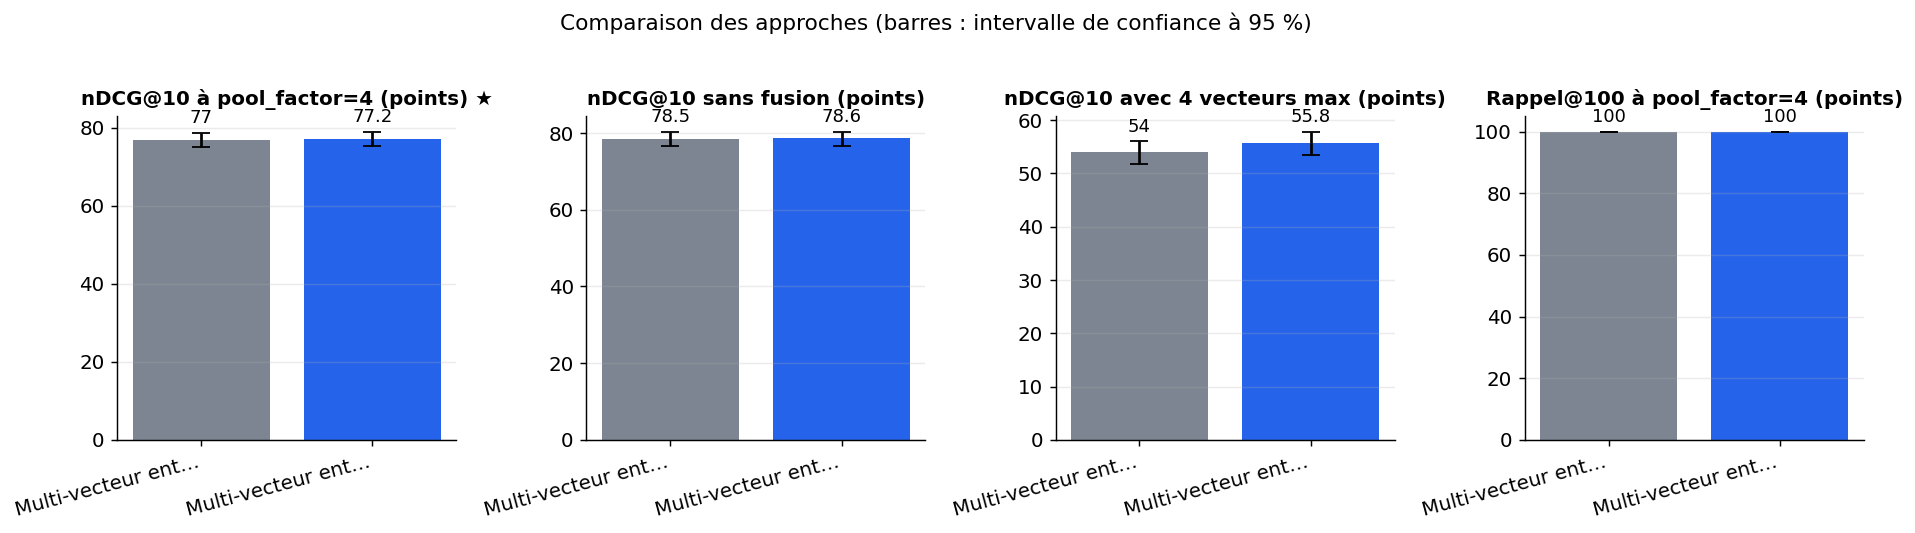

*Figure — nDCG@10 à pool_factor=4 (métrique principale), sans fusion et avec 4 vecteurs au plus, puis rappel@100, sur le jeu principal. Les barres d'erreur sont les intervalles de confiance à 95 % (bootstrap sur les requêtes).*

In [38]:
METRIC_LABELS = {
    "ndcg_at_10": "nDCG@10 à pool_factor=4 (points)",
    "ndcg_at_10_unpooled": "nDCG@10 sans fusion (points)",
    "ndcg_at_10_max_tokens_4": "nDCG@10 avec 4 vecteurs max (points)",
    "score_retention_ratio": "Rétention du score à pool_factor=4 (ratio)",
    "recall_at_100": "Rappel@100 à pool_factor=4 (points)",
    "mean_vectors_per_document": "Vecteurs par passage à pool_factor=4",
    "index_size_mb": "Taille d'index fp16 du corpus évalué (Mo)",
    "ndcg_at_10_nanobeir_fr": "nDCG@10 moyen NanoBEIR-fr à pool_factor=4 (points)",
}
dataset_info = {"name": MAIN_DATASET if PHASE == "public" else "données internes",
                "config": "default" if PHASE == "public" else "interne",
                "split": "test" if PHASE == "public" else "évaluation (découpage par passage)",
                "n_examples": int(len(main_set.queries))}
computed = {key: approach_metrics(key) for key in ("reference", "new")}
logs = {"reference": reference_log, "new": new_log}
results = save_results({
    "primary_metric": "ndcg_at_10", "direction": "max", "metric_labels": METRIC_LABELS, "dataset": dataset_info,
    "approaches": [{"name": APPROACH_NAMES[key], "role": key, "metrics": computed[key][0], "ci95": computed[key][1],
                    "latency_ms": latency_summary(computed[key][2]), "notes": approach_notes(key, logs[key])}
                   for key in computed],
})
display(results_table(results))
plot_comparison(results, metrics=["ndcg_at_10", "ndcg_at_10_unpooled", "ndcg_at_10_max_tokens_4", "recall_at_100"],
                caption="nDCG@10 à pool_factor=4 (métrique principale), sans fusion et avec 4 vecteurs au plus, puis rappel@100, sur le jeu principal. Les barres d'erreur sont les intervalles de confiance à 95 % (bootstrap sur les requêtes).")

### Verdict, écrit à l'avance
1. **Éligibilité** : la borne basse du nDCG@10 sans fusion de chaque modèle doit dépasser le plancher aléatoire. Sinon, le résultat est **non concluant**.
2. **Gain** : on calcule par bootstrap apparié l'écart de nDCG@10 (nouvelle − référence) à pool_factor=4.
3. **Hypothèse** : un gain d'au moins 2 points avec une borne basse positive, une rétention d'au moins 97 % pour la nouvelle approche et de 95 % au plus pour la référence.

In [39]:
reference_pooled = evaluations["reference"][("main", "pool_factor=4")]
new_pooled = evaluations["new"][("main", "pool_factor=4")]
delta, delta_ci = with_ci(new_pooled["ndcg"], reference_pooled["ndcg"],
                          lambda a, b: float(np.mean(np.asarray(a) - np.asarray(b))))
random_floor = random_ndcg(main_set)
eligible = all(computed[key][1]["ndcg_at_10_unpooled"][0] > random_floor for key in computed)
retention_new = computed["new"][0]["score_retention_ratio"]
retention_ref = computed["reference"][0]["score_retention_ratio"]
checks = pd.DataFrame([
    {"critère": "Les deux modèles battent le hasard (borne basse sans fusion)", "valeur": f"hasard : {random_floor:.2f} pts", "atteint": eligible},
    {"critère": "Gain nDCG@10 ≥ 2 pts à pool_factor=4, borne basse > 0", "valeur": f"{delta:+.2f} [{delta_ci[0]:+.2f} ; {delta_ci[1]:+.2f}]", "atteint": delta >= 2 and delta_ci[0] > 0},
    {"critère": "Rétention de la nouvelle approche ≥ 97 %", "valeur": f"{retention_new:.1%}", "atteint": retention_new >= 0.97},
    {"critère": "Rétention de la référence ≤ 95 %", "valeur": f"{retention_ref:.1%}", "atteint": retention_ref <= 0.95},
])
display(checks)
if not eligible:
    verdict = "Non concluant : au moins un modèle ne fait pas mieux qu'un classement aléatoire ; l'écart n'est pas interprétable."
elif checks["atteint"].iloc[1:].all():
    verdict = "Hypothèse confirmée : l'entraînement conscient du pooling préserve nettement mieux la qualité d'un index ÷4."
elif delta_ci[0] > 0:
    verdict = "Gain significatif à pool_factor=4, mais l'hypothèse chiffrée n'est pas entièrement atteinte (voir le tableau)."
elif delta_ci[1] < 0:
    verdict = "La nouvelle approche fait significativement moins bien que la référence compressée après coup."
else:
    verdict = "Non concluant : l'intervalle apparié du gain contient 0."
print(verdict)

,critère,valeur,atteint
0,Les deux modèles battent le hasard (borne bass...,hasard : 7.71 pts,True
1,"Gain nDCG@10 ≥ 2 pts à pool_factor=4, borne ba...",+0.21 [-0.57 ; +1.05],False
2,Rétention de la nouvelle approche ≥ 97 %,98.2%,True
3,Rétention de la référence ≤ 95 %,98.0%,False


Non concluant : l'intervalle apparié du gain contient 0.


## 6. Analyse des résultats

### Qualité en fonction du nombre de vecteurs stockés
Chaque point correspond à un réglage de compression. Plus on va à gauche, plus l'index est petit. Si la nouvelle approche tient sa promesse, sa courbe doit **moins descendre** quand on compresse, surtout à pool_factor=4, le niveau vu à l'entraînement, et à max_tokens=4.

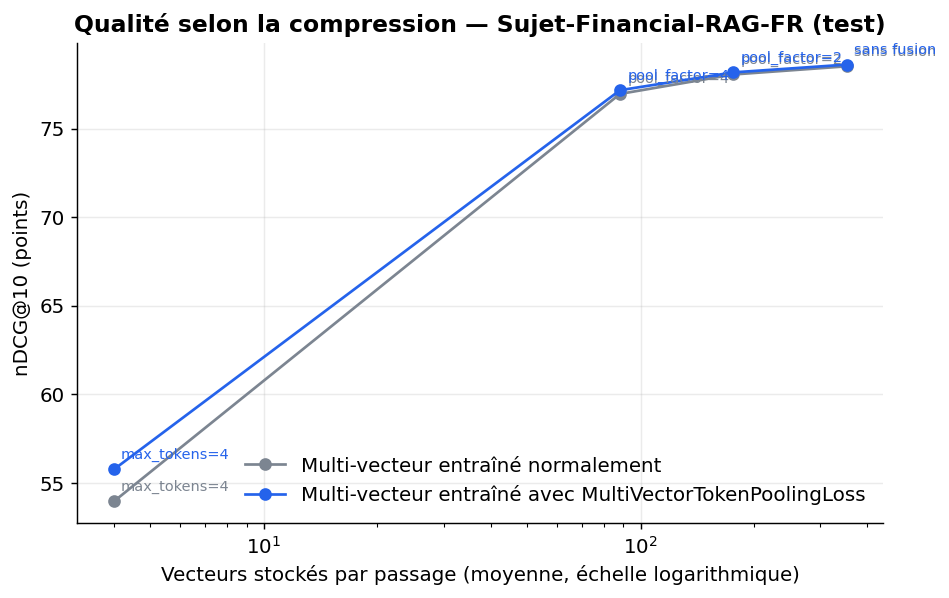

*Figure — nDCG@10 du jeu principal selon le nombre moyen de vecteurs gardés par passage (de droite à gauche : sans fusion, pool_factor=2, pool_factor=4, 4 vecteurs au plus). Une courbe qui reste haute vers la gauche résiste mieux à la compression.*

In [40]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for key in ("reference", "new"):
    points = [evaluations[key][("main", config_name)] for config_name in POOL_CONFIGS]
    xs = [point["mean_vectors"] for point in points]
    ys = [point["ndcg"].mean() for point in points]
    ax.plot(xs, ys, marker="o", color=COLORS[key], label=APPROACH_NAMES[key])
    for config_name, x, y in zip(POOL_CONFIGS, xs, ys):
        ax.annotate(config_name, (x, y), textcoords="offset points", xytext=(4, 6), fontsize=8, color=COLORS[key])
ax.set_xscale("log")
ax.set(xlabel="Vecteurs stockés par passage (moyenne, échelle logarithmique)", ylabel="nDCG@10 (points)",
       title=f"Qualité selon la compression — {main_set.name}")
ax.legend()
save_figure(fig, "quality_vs_vectors", "nDCG@10 du jeu principal selon le nombre moyen de vecteurs gardés par passage (de droite à gauche : sans fusion, pool_factor=2, pool_factor=4, 4 vecteurs au plus). Une courbe qui reste haute vers la gauche résiste mieux à la compression.")

### Rétention par jeu
Le gain se répète-t-il d'un jeu à l'autre ? Le tableau donne la rétention (score compressé / score non compressé, en %) pour chaque réglage. La figure montre pool_factor=4, avec le seuil de 97 % de l'hypothèse. En phase publique, cela inclut les sous-jeux NanoBEIR-fr, qui reproduisent le protocole de la source.

approche                                     Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss  \
jeu                           réglage                                                                  
NanoBEIR-fr NanoArguAna       max_tokens=4                                               100.3         
                              pool_factor=2                                               96.2         
                              pool_factor=4                                               93.3         
NanoBEIR-fr NanoFiQA2018      max_tokens=4                                                52.2         
                              pool_factor=2                                               97.7         
                              pool_factor=4                                               97.6         
NanoBEIR-fr NanoNFCorpus      max_tokens=4                                                42.2         
                              pool_factor=2                                               99.9         
                              pool_factor=4                                               94.7         
NanoBEIR-fr NanoSciFact       max_tokens=4                                                48.8         
                              pool_factor=2                                               96.0         
                              pool_factor=4                                               94.7         
Sujet-Financial-RAG-FR (test) max_tokens=4                                                70.9         
                              pool_factor=2                                               99.4         
                              pool_factor=4                                               98.2         

approche                                     Multi-vecteur entraîné normalement  
jeu                           réglage                                            
NanoBEIR-fr NanoArguAna       max_tokens=4                                105.9  
                              pool_factor=2                                96.9  
                              pool_factor=4                                94.0  
NanoBEIR-fr NanoFiQA2018      max_tokens=4                                 41.6  
                              pool_factor=2                                98.1  
                              pool_factor=4                               100.1  
NanoBEIR-fr NanoNFCorpus      max_tokens=4                                 39.9  
                              pool_factor=2                                99.9  
                              pool_factor=4                                95.0  
NanoBEIR-fr NanoSciFact       max_tokens=4                                 46.6  
                              pool_factor=2                                96.7  
                              pool_factor=4                                89.3  
Sujet-Financial-RAG-FR (test) max_tokens=4                                 68.7  
                              pool_factor=2                                99.4  
                              pool_factor=4                                98.0

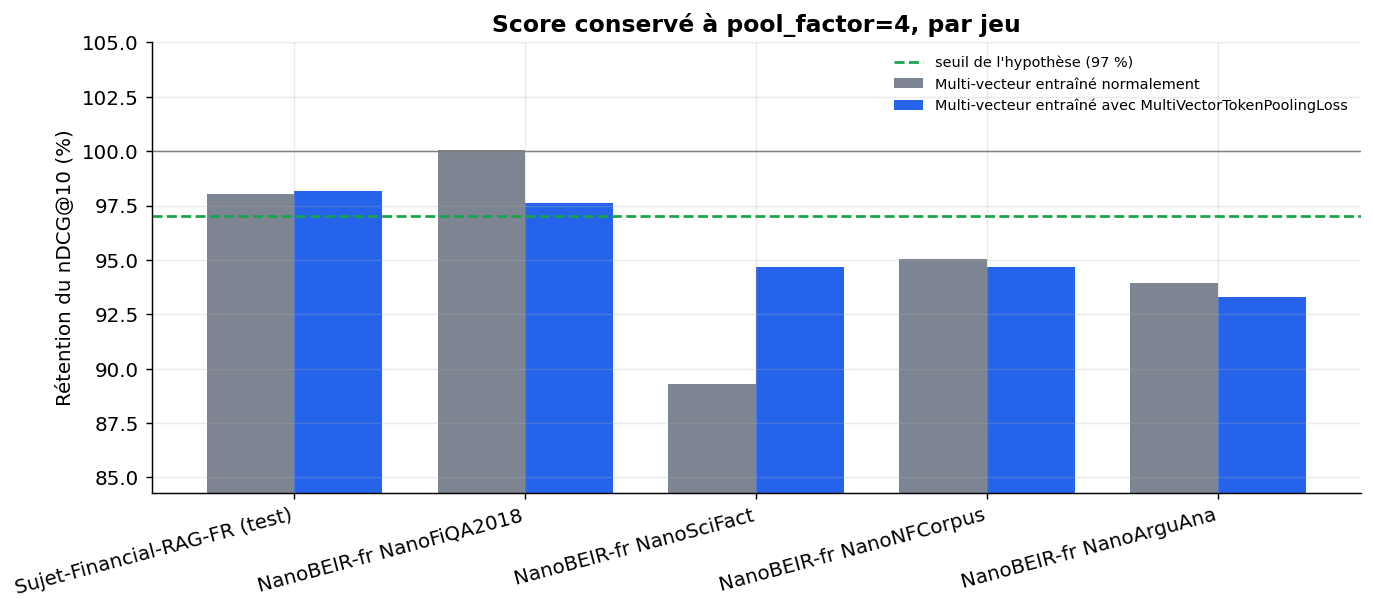

*Figure — Part du nDCG@10 non compressé conservée à pool_factor=4, pour chaque jeu et chaque approche. Au-dessus du trait vert, l'objectif de 97 % est atteint ; au-dessus de 100 %, la compression améliore même le classement.*

In [41]:
retention_rows = []
for set_key, rset in all_sets.items():
    for key in ("reference", "new"):
        base = evaluations[key][(set_key, "sans fusion")]["ndcg"].mean()
        for config_name in ("pool_factor=2", "pool_factor=4", "max_tokens=4"):
            pooled_score = evaluations[key][(set_key, config_name)]["ndcg"].mean()
            retention_rows.append({"jeu": rset.name, "approche": APPROACH_NAMES[key], "réglage": config_name,
                                   "rétention (%)": 100 * pooled_score / base if base > 0 else np.nan})
retention_table = pd.DataFrame(retention_rows)
display(retention_table.pivot_table(index=["jeu", "réglage"], columns="approche", values="rétention (%)").round(1))
at_four = retention_table[retention_table["réglage"] == "pool_factor=4"]
set_names = list(dict.fromkeys(at_four["jeu"]))
positions, width = np.arange(len(set_names)), 0.38
fig, ax = plt.subplots(figsize=(max(6.5, 2.4 * len(set_names)), 4.5))
for offset, key in [(-width / 2, "reference"), (width / 2, "new")]:
    values = at_four[at_four["approche"] == APPROACH_NAMES[key]].set_index("jeu").loc[set_names, "rétention (%)"]
    ax.bar(positions + offset, values.to_numpy(), width, color=COLORS[key], label=APPROACH_NAMES[key])
ax.axhline(97, color=COLORS["good"], linestyle="--", label="seuil de l'hypothèse (97 %)")
ax.axhline(100, color="grey", linewidth=0.8)
lowest = np.nanmin(at_four["rétention (%)"].to_numpy()) if at_four["rétention (%)"].notna().any() else 90
ax.set_ylim(max(0, min(lowest, 95) - 5), max(105, np.nanmax(at_four["rétention (%)"].fillna(0).to_numpy()) + 3))
ax.set_xticks(positions, set_names, rotation=15, ha="right")
ax.set(ylabel="Rétention du nDCG@10 (%)", title="Score conservé à pool_factor=4, par jeu")
ax.legend(fontsize=8)
save_figure(fig, "retention_by_dataset", "Part du nDCG@10 non compressé conservée à pool_factor=4, pour chaque jeu et chaque approche. Au-dessus du trait vert, l'objectif de 97 % est atteint ; au-dessus de 100 %, la compression améliore même le classement.")

### La perte due à la fusion selon la longueur des passages
Un passage long a beaucoup de tokens à fusionner, un passage court très peu. On regroupe les requêtes en tiers selon la longueur, en tokens lus, de leur passage pertinent. Pour chaque tiers, on calcule la **variation moyenne du nDCG@10** entre pool_factor=4 et l'absence de fusion. Une barre proche de 0 signifie que la compression ne coûte rien.

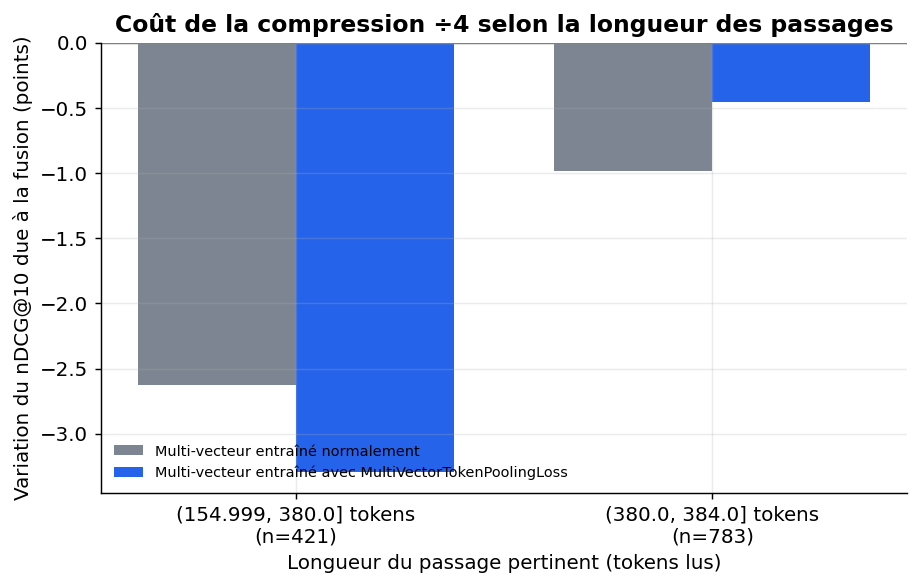

*Figure — Variation moyenne du nDCG@10 entre pool_factor=4 et l'absence de fusion, par tiers de longueur du passage pertinent. Une barre sous 0 indique une perte due à la compression ; plus elle est courte, mieux le modèle résiste.*

,Multi-vecteur entraîné normalement,Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss
groupe,,
"(154.999, 380.0]",-2.62,-3.29
"(380.0, 384.0]",-0.99,-0.45


In [42]:
doc_lengths = dict(zip(main_set.corpus, (len(vectors) for vectors in reference_encoded["main"]["docs"])))
relevant_length = np.array([max(doc_lengths[doc_id] for doc_id in main_set.qrels[query_id]) for query_id in main_set.queries])
edges = np.unique(np.quantile(relevant_length, [0, 1 / 3, 2 / 3, 1]))
if len(edges) >= 3:
    groups = np.asarray(pd.cut(relevant_length, edges, include_lowest=True).astype(str))
else:
    groups = np.full(len(relevant_length), "tous")
order = list(dict.fromkeys(groups[np.argsort(relevant_length, kind="stable")]))
by_length = pd.DataFrame({"groupe": groups})
for key in ("reference", "new"):
    by_length[key] = evaluations[key][("main", "pool_factor=4")]["ndcg"] - evaluations[key][("main", "sans fusion")]["ndcg"]
summary = by_length.groupby("groupe")[["reference", "new"]].mean().loc[order]
counts = by_length.groupby("groupe").size().loc[order]
positions, width = np.arange(len(order)), 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, key in [(-width / 2, "reference"), (width / 2, "new")]:
    ax.bar(positions + offset, summary[key].to_numpy(), width, color=COLORS[key], label=APPROACH_NAMES[key])
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(positions, [f"{group} tokens\n(n={counts[group]})" for group in order])
ax.set(xlabel="Longueur du passage pertinent (tokens lus)", ylabel="Variation du nDCG@10 due à la fusion (points)",
       title="Coût de la compression ÷4 selon la longueur des passages")
ax.legend(fontsize=8)
save_figure(fig, "pooling_loss_by_length", "Variation moyenne du nDCG@10 entre pool_factor=4 et l'absence de fusion, par tiers de longueur du passage pertinent. Une barre sous 0 indique une perte due à la compression ; plus elle est courte, mieux le modèle résiste.")
display(summary.rename(columns=APPROACH_NAMES).round(2))

### Exemples de désaccords (phase publique seulement)
On affiche des requêtes dont le passage pertinent entre dans le top 10 pour une approche mais pas pour l'autre, puis des requêtes manquées par les deux. Le rang est celui du premier passage pertinent à pool_factor=4. `NaN` signifie que ce passage est au-delà du rang 100. Ces exemples aident à voir si les erreurs tiennent à la compression ou à la question elle-même.

In [43]:
if PHASE == "public":
    ranks = pd.DataFrame({
        "question": [text[:110] for text in main_set.queries.values()],
        "rang référence": evaluations["reference"][("main", "pool_factor=4")]["first_rank"],
        "rang nouvelle": evaluations["new"][("main", "pool_factor=4")]["first_rank"],
    })
    in_top_ref, in_top_new = ranks["rang référence"] <= 10, ranks["rang nouvelle"] <= 10
    print(f"Top 10 : retrouvé par la nouvelle seulement {int((in_top_new & ~in_top_ref).sum())}, "
          f"par la référence seulement {int((in_top_ref & ~in_top_new).sum())}, "
          f"par aucune {int((~in_top_ref & ~in_top_new).sum())} (sur {len(ranks)} requêtes)")
    examples = pd.concat([
        ranks[in_top_new & ~in_top_ref].head(3).assign(cas="nouvelle seulement"),
        ranks[in_top_ref & ~in_top_new].head(3).assign(cas="référence seulement"),
        ranks[~in_top_ref & ~in_top_new].head(3).assign(cas="manqué par les deux"),
    ])
    display(examples)

Top 10 : retrouvé par la nouvelle seulement 13, par la référence seulement 14, par aucune 79 (sur 1204 requêtes)


,question,rang référence,rang nouvelle,cas
20,Quelles mesures ont été prises pour compenser ...,14.0,9.0,nouvelle seulement
33,Comment le résultat net part du groupe est-il ...,11.0,4.0,nouvelle seulement
159,Quelle est la variation des frais de gestion d...,12.0,9.0,nouvelle seulement
28,Comment les crédits aux particuliers de BNL bc...,8.0,12.0,référence seulement
199,Quelles sont les implications réglementaires p...,4.0,17.0,référence seulement
273,Quelle est la valeur de la réserve de liquidit...,7.0,12.0,référence seulement
13,Quel est le résultat de l'exercice au 31 mars ...,21.0,22.0,manqué par les deux
68,Quelles activités de la Société Générale sont ...,26.0,27.0,manqué par les deux
90,Quel est le retour sur capital investi prévu p...,13.0,17.0,manqué par les deux


### À retenir
- **Si** l'écart apparié de nDCG@10 à pool_factor=4 a une borne basse positive, entraîner « conscient du pooling » rend l'index ÷4 plus sûr en français. **Si** l'intervalle contient 0, rien ne justifie d'abandonner l'entraînement ordinaire suivi d'une compression après coup.
- La **rétention** se lit modèle par modèle. Un modèle qui garde plus de 97 % de son score peut malgré tout être moins bon dans l'absolu, d'où le nDCG@10 sans fusion rapporté à côté.
- Le réglage `max_tokens=4` met la méthode à l'épreuve : c'est là que l'écart entre les approches devrait être le plus visible, si l'effet existe.
- La taille d'index et le nombre de vecteurs sont **identiques** pour les deux approches à réglage égal. La décision se joue donc sur la qualité, la latence de requête et le coût du clustering à l'indexation, ce dernier n'étant pas mesuré ici.
- Ce résultat repose sur un seul tirage : un seul entraînement par approche et une seule graine. Un écart de moins de 1 à 2 points demande d'autres graines avant toute conclusion.

## 7. Bilan

> **Verdict** (confiance moyenne). La comparaison est correcte sur le plan du protocole : mêmes données, même initialisation, mêmes lots, même nombre de pas (188), mêmes évaluations appariées, sans fuite apparente. À l'échelle complète (1 204 requêtes, GPU), à pool_factor=4, le nDCG@10 est de 77,16 pour la nouvelle approche contre 76,96 pour la référence, soit +0,21 point avec un intervalle apparié de [−0,57 ; +1,05]. Les rétentions sont presque identiques (98,2 % vs 98,0 %). L'hypothèse (≥ 2 points, 97 % vs ≤ 95 %) n'est pas confirmée et le résultat est non concluant, et non une preuve d'absence d'effet. La source (+2,2 points, 97,8 % vs 94,6 %) n'est pas reproduite, mais le protocole diffère (un seul entraînement de 6 000 paires, une perte réimplémentée, un jeu financier facile où la référence perd déjà peu). Sous max_tokens=4, l'avantage apparent (+1,8 point) reste non testé.

*Échelle complète : 1204 exemples de test de `sujet-ai/Sujet-Financial-RAG-FR-Dataset` (GPU T4 (Google Colab), 21 min). La mécanique avait d'abord été validée à l'échelle réduite (100 exemples, CPU).*

| Approche | nDCG@10 à pool_factor=4 ★ ↑ | nDCG@10 sans fusion ↑ | nDCG@10 avec 4 vecteurs max ↑ | Rappel@100 ↑ | Rétention du score ↑ | Vecteurs par passage ↓ | Taille d'index (Mo) ↓ | nDCG@10 moyen NanoBEIR-fr ↑ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|---|
| Multi-vecteur entraîné normalement (référence) | 77 [75 ; 78,8] | 78,5 [76,6 ; 80,3] | 54 [51,8 ; 56,1] | 100 [100 ; 100] | 0,98 [0,97 ; 0,99] | 88,2 | 1,35 | **38,6** | 22,9 |
| Multi-vecteur entraîné avec MultiVectorTokenPoolingLoss (nouvelle approche) | **77,2 [75,3 ; 79,1]** | **78,6 [76,7 ; 80,4]** | **55,8 [53,5 ; 57,9]** | 100 [100 ; 100] | **0,982 [0,973 ; 0,99]** | 88,2 | 1,35 | 38,3 | 23,4 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Le résultat concerne une réimplémentation de l'objectif, pas la perte livrée par la bibliothèque ; l'absence d'effet pourrait venir d'écarts d'implémentation.
- L'écart observé est dans le bruit d'un seul entraînement ; on ne peut conclure ni à l'absence ni à la présence d'un petit effet réel.
- Sur ce jeu facile, la compression coûte déjà peu à un modèle ordinaire ; l'absence de gain ne prouve pas que l'entraînement conscient du pooling soit inutile sur des corpus plus exigeants.

**Limites**

- Un seul entraînement par approche et une seule graine : on ne connaît pas la variance entre graines, donc un écart de 1 à 2 points reste fragile.
- Une seule paire pertinente par question dans le jeu principal, avec des questions probablement générées automatiquement ; NanoBEIR-fr est traduit automatiquement et peu centré sur les services financiers.
- L'entraînement se fait sur quelques milliers de paires, avec des négatifs dans le lot, au lieu de 120 000 triplets avec un négatif difficile comme dans la source.
- La perte est réimplémentée en PyTorch, et le clustering de Ward est calculé par SciPy sur CPU ; le coût d'indexation n'est pas mesuré.
- Pas de comparaison à une recherche hybride ni à un index approché : la recherche est exhaustive sur des corpus de taille modeste.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, l'expérience porte sur 300 paires d'entraînement, des passages de 128 tokens au plus et des requêtes de 64 tokens au plus. Les lots comptent 16 paires, et chaque entraînement a un budget de 420 s. L'évaluation utilise 100 requêtes du test et un corpus de 500 passages, ainsi qu'un seul sous-jeu NanoBEIR-fr (NanoFiQA2018 : 50 requêtes, 300 passages). Le modèle est le même qu'à l'échelle complète, sans substitut.

**Améliorations possibles**

- La tendance à l'avantage de la nouvelle approche en compression extrême est suggestive, mais non démontrée statistiquement.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).